# Immigration flows vs. push factors (normalized indicators)

The same heatmaps as before, rebuilt with the **31 normalized indicators** in `migration_panel_normalized.csv`,
grouped into the five push-factor categories plus a pull factor (diaspora).

- Indicators run **down the side** (there are too many to fit across), grouped by category.
- All indicators are from the **previous year** (`_lag1`), except diaspora (a single 2023 value per country).
- Same red-gray-blue colors as before.
- Homicide gaps are filled with IHME estimates (see the `homicides_source` column); see the codebook for every column's source.

Files needed in the same folder: `migration_panel_normalized.csv` (indicators) and `migration_panel_combined.csv`
(only used for the raw counts that rank the top sending countries).

## Outcome measures (focus: people coming to the U.S.)

| Outcome | Column | Role |
|---|---|---|
| Refugee arrivals | `refugees_per_100k` | **Entry measure.** People resettled from abroad that year. |
| Apprehensions | `apprehensions_per_100k` | **Entry measure.** Attempted unauthorized entries (DHS; 2023 = Border Patrol only, 12 countries). |
| Green cards, excl. refugee/asylee | `green_cards_excl_refugee_asylee_per_100k` | **Slower measure of long-term ties.** New permanent residents, including people already here who adjust status, minus refugee/asylee adjustments (already counted as refugees/asylum, and mostly Cuban Adjustment Act cases). No FY2017. |
| Asylum grants (affirmative) | `asylum_grants_per_100k` | **Secondary.** Applicants are already in the U.S., often for years, so grant year ≠ entry year. |

Humanitarian parole (`parole_major_programs`) is an entry measure too, but it exists for only 5 countries in FY2023,
so it can't be correlated across country-years and is left out of the charts. See `dataset_methods.ipynb` for every choice.

**Footnote: Compacts of Free Association.** Citizens of the Marshall Islands, Micronesia and Palau can live and work in the
U.S. without a visa, so most never need a green card. Their migration barely shows up in these measures,
and they appear as outliers in the green card charts. Section 9 breaks green cards down by type.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr

df = pd.read_csv("migration_panel_normalized.csv")
counts = pd.read_csv("migration_panel_combined.csv")[["iso3", "country", "year", "green_cards", "green_cards_excl_refugee_asylee",
                                                      "refugees", "asylum_grants", "apprehensions"]]
print(df.shape)

(2000, 46)


## Variables and labels
Edit `categories` to add, drop or rename indicators.

In [2]:
outcomes = {
    "refugees_per_100k":                        "Refugees",
    "apprehensions_per_100k":                   "Apprehensions",
    "green_cards_excl_refugee_asylee_per_100k": "Green cards*",
    "asylum_grants_per_100k":                   "Asylum grants",
}
# * Green cards = new permanent residents excluding refugee/asylee adjustments

categories = {
    "Economic hardship": {
        "gdp_per_capita_lag1":         "GDP per capita",
        "gdp_growth_pct_lag1":         "GDP growth %",
        "unemployment_pct_lag1":       "Unemployment %",
        "youth_unemployment_pct_lag1": "Youth unemployment %",
        "inflation_pct_lag1":          "Inflation %",
    },
    "Violence & conflict": {
        "idps_conflict_per_100k_lag1":              "Conflict IDPs /100k",
        "new_displacements_conflict_per_100k_lag1": "New conflict displacements /100k",
        "battle_deaths_per_100k_lag1":              "Battle deaths /100k",
        "homicides_per_100k_lag1":                  "Homicides /100k",
        "vdem_political_violence_lag1":             "Political violence (↑ = more)",
    },
    "Persecution & discrimination": {
        "vdem_electoral_democracy_lag1":               "Electoral democracy",
        "vdem_physical_integrity_lag1":                "Freedom from killings/torture",
        "vdem_religious_freedom_lag1":                 "Religious freedom",
        "vdem_power_equality_social_group_lag1":       "Equality: social groups",
        "vdem_power_equality_gender_lag1":             "Equality: gender",
        "vdem_power_equality_sexual_orientation_lag1": "Equality: sexual orientation",
    },
    "Environmental disasters": {
        "disaster_affected_per_100k_lag1":          "Disaster-affected /100k",
        "disaster_deaths_per_100k_lag1":            "Disaster deaths /100k",
        "idps_disaster_per_100k_lag1":              "Disaster IDPs /100k",
        "new_displacements_disaster_per_100k_lag1": "New disaster displacements /100k",
        "undernourishment_pct_lag1":                "Undernourishment %",
        "food_production_index_lag1":               "Food production index",
    },
    "Public services": {
        "life_expectancy_lag1":                "Life expectancy",
        "under5_mortality_per_1k_lag1":        "Under-5 mortality /1k",
        "basic_water_access_pct_lag1":         "Basic water access %",
        "electricity_access_pct_lag1":         "Electricity access %",
        "health_spending_per_capita_usd_lag1": "Health spending per capita",
    },
    "Pull factor": {
        "diaspora_in_us_per_100k_origin_pop": "U.S. diaspora /100k origin pop.",
    },
}

indicators = {col: label for group in categories.values() for col, label in group.items()}
print(len(indicators), "indicators")

28 indicators


## Shared plotting helper
Builds a grouped heatmap: a bold header row for each category, then its indicators.

In [3]:
CMAP = LinearSegmentedColormap.from_list(
    "red_gray_blue", ["#b8302f", "#e34948", "#f0efec", "#3987e5", "#1c5cab"]
)
CMAP.set_bad("#ffffff")

def grouped_rows():
    """Row layout: (kind, column, label) with a header row before each category."""
    rows = []
    for cat, cols in categories.items():
        rows.append(("header", None, cat))
        rows += [("row", c, l) for c, l in cols.items()]
    return rows

def draw_grouped_heatmap(color_vals, cell_text, col_labels, vmin, vmax, cbar_label, title, filename,
                         width, dark_ink):
    """color_vals / cell_text: dict column -> list of values / strings, one per heatmap column."""
    rows = grouped_rows()
    mat = np.array([[np.nan] * len(col_labels) if k == "header" else color_vals[c] for k, c, _ in rows], float)

    fig, ax = plt.subplots(figsize=(width, 0.36 * len(rows) + 1.6))
    im = ax.imshow(np.ma.masked_invalid(mat), cmap=CMAP, vmin=vmin, vmax=vmax, aspect="auto")

    ax.set_xticks(np.arange(-0.5, len(col_labels)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(rows)), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="minor", length=0)
    ax.set_xticks(range(len(col_labels)), col_labels, rotation=35, ha="left", rotation_mode="anchor")
    ax.set_yticks(range(len(rows)), [l for _, _, l in rows])
    ax.tick_params(which="major", length=0, labelsize=10)
    ax.xaxis.tick_top()
    for s in ax.spines.values():
        s.set_visible(False)

    for tick, (kind, _, _) in zip(ax.get_yticklabels(), rows):
        if kind == "header":
            tick.set_fontweight("bold"); tick.set_fontsize(11)

    for i, (kind, c, _) in enumerate(rows):
        if kind == "header":
            continue
        for j, txt in enumerate(cell_text[c]):
            v = color_vals[c][j]
            ink = "white" if dark_ink(v) else "#1f1f1d"
            ax.text(j, i, txt, ha="center", va="center", fontsize=9, fontweight="bold", color=ink)

    cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, shrink=0.5)
    cbar.set_label(cbar_label, fontsize=10)
    cbar.outline.set_visible(False)
    ax.set_title(title, fontsize=12, pad=12, loc="left")
    plt.tight_layout()
    plt.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()

---
# 1. Correlation heatmap

Spearman rank correlation between each indicator and each immigration type (per 100k), pooled over all country-years,
dropping missing values pair by pair. Blue = positive, red = negative, gray = none. Color scale fixed at ±0.5.

In [4]:
rho, nobs = {}, {}
for col in indicators:
    rho[col], nobs[col] = [], []
    for o in outcomes:
        pair = df[[o, col]].dropna()
        rho[col].append(spearmanr(pair[o], pair[col])[0])
        nobs[col].append(len(pair))

corr_table = pd.DataFrame(rho, index=outcomes.values()).T.rename(index=indicators).round(2)
corr_table

,Refugees,Apprehensions,Green cards*,Asylum grants
GDP per capita,-0.44,0.10,0.23,-0.52
GDP growth %,0.10,-0.05,-0.02,0.09
Unemployment %,-0.07,0.17,0.10,0.06
Youth unemployment %,-0.13,0.19,0.13,-0.01
Inflation %,0.25,-0.10,-0.11,0.31
Conflict IDPs /100k,0.47,-0.08,-0.15,0.44
New conflict displacements /100k,0.44,-0.11,-0.16,0.37
Battle deaths /100k,0.40,-0.18,-0.21,0.32
Homicides /100k,0.19,0.17,0.13,0.23
Political violence (↑ = more),0.37,-0.17,-0.15,0.45


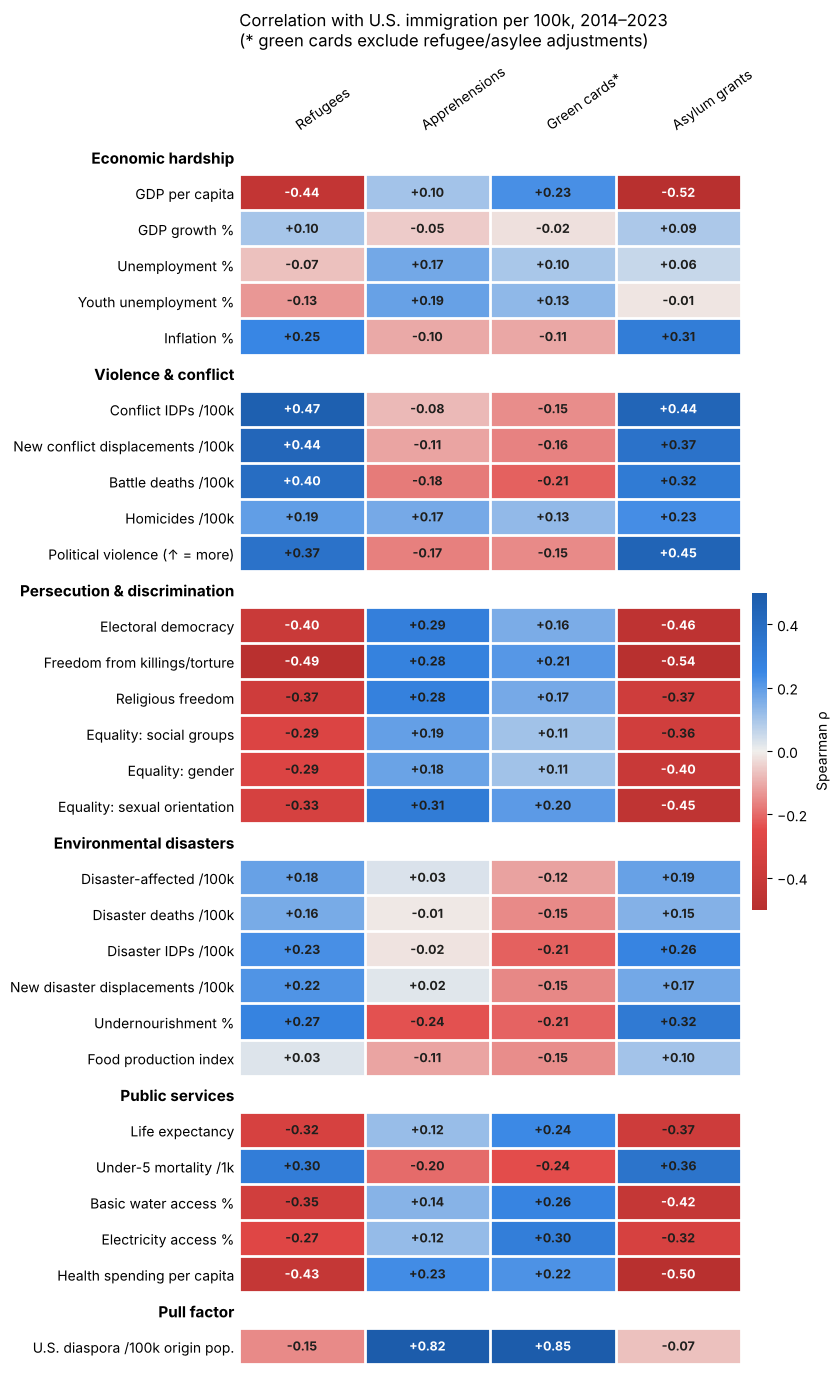

In [5]:
draw_grouped_heatmap(
    color_vals=rho,
    cell_text={c: [f"{r:+.2f}" for r in v] for c, v in rho.items()},
    col_labels=list(outcomes.values()),
    vmin=-0.5, vmax=0.5,
    cbar_label="Spearman ρ",
    title="Correlation with U.S. immigration per 100k, 2014–2023\n(* green cards exclude refugee/asylee adjustments)",
    filename="normalized_correlation_heatmap.png",
    width=8.5,
    dark_ink=lambda v: abs(v) > 0.38,
)

---
# 2. Top sending countries: indicator profiles

Countries ranked by **raw totals** over 2014–2023. Each cell shows the country's **average value**;
color = its **percentile among all countries** (blue = above the median country, red = below, gray = about average).
Blue does not mean good or bad: for some rows (e.g. mortality, homicides) blue is the worse end.

In [6]:
country_avg = df.groupby("country")[list(indicators)].mean()
pct = country_avg.rank(pct=True) * 100

def fmt(col, v):
    if pd.isna(v):
        return "n/a"
    if v == 0:
        return "0"
    if col in ("gdp_per_capita_lag1", "health_spending_per_capita_usd_lag1"):
        return f"${v/1000:,.1f}k" if v >= 1000 else f"${v:,.0f}"
    if "pct" in col:
        return f"{v:.1f}%"
    if col.startswith("vdem_"):
        return f"{v:.2f}"
    if "per_100k" in col or "per_1k" in col:
        return f"{v:,.0f}" if v >= 100 else (f"{v:.1f}" if v >= 1 else f"{v:.2f}")
    return f"{v:.1f}"

def plot_top_senders(count_col, type_label, filename, n=5):
    totals = counts.groupby("country")[count_col].sum().sort_values(ascending=False)
    top = totals.head(n).index.tolist()
    draw_grouped_heatmap(
        color_vals={c: [pct.loc[k, c] for k in top] for c in indicators},
        cell_text={c: [fmt(c, country_avg.loc[k, c]) for k in top] for c in indicators},
        col_labels=[f"{k}\n({totals[k]:,.0f})" for k in top],
        vmin=0, vmax=100,
        cbar_label="Percentile among all countries",
        title=f"Top {n} countries by {type_label}, 2014–2023 (total in parentheses)",
        filename=filename,
        width=4.2 + 1.15 * n,
        dark_ink=lambda p: (not pd.isna(p)) and (p >= 80 or p <= 25),
    )

## Refugees (top 10)

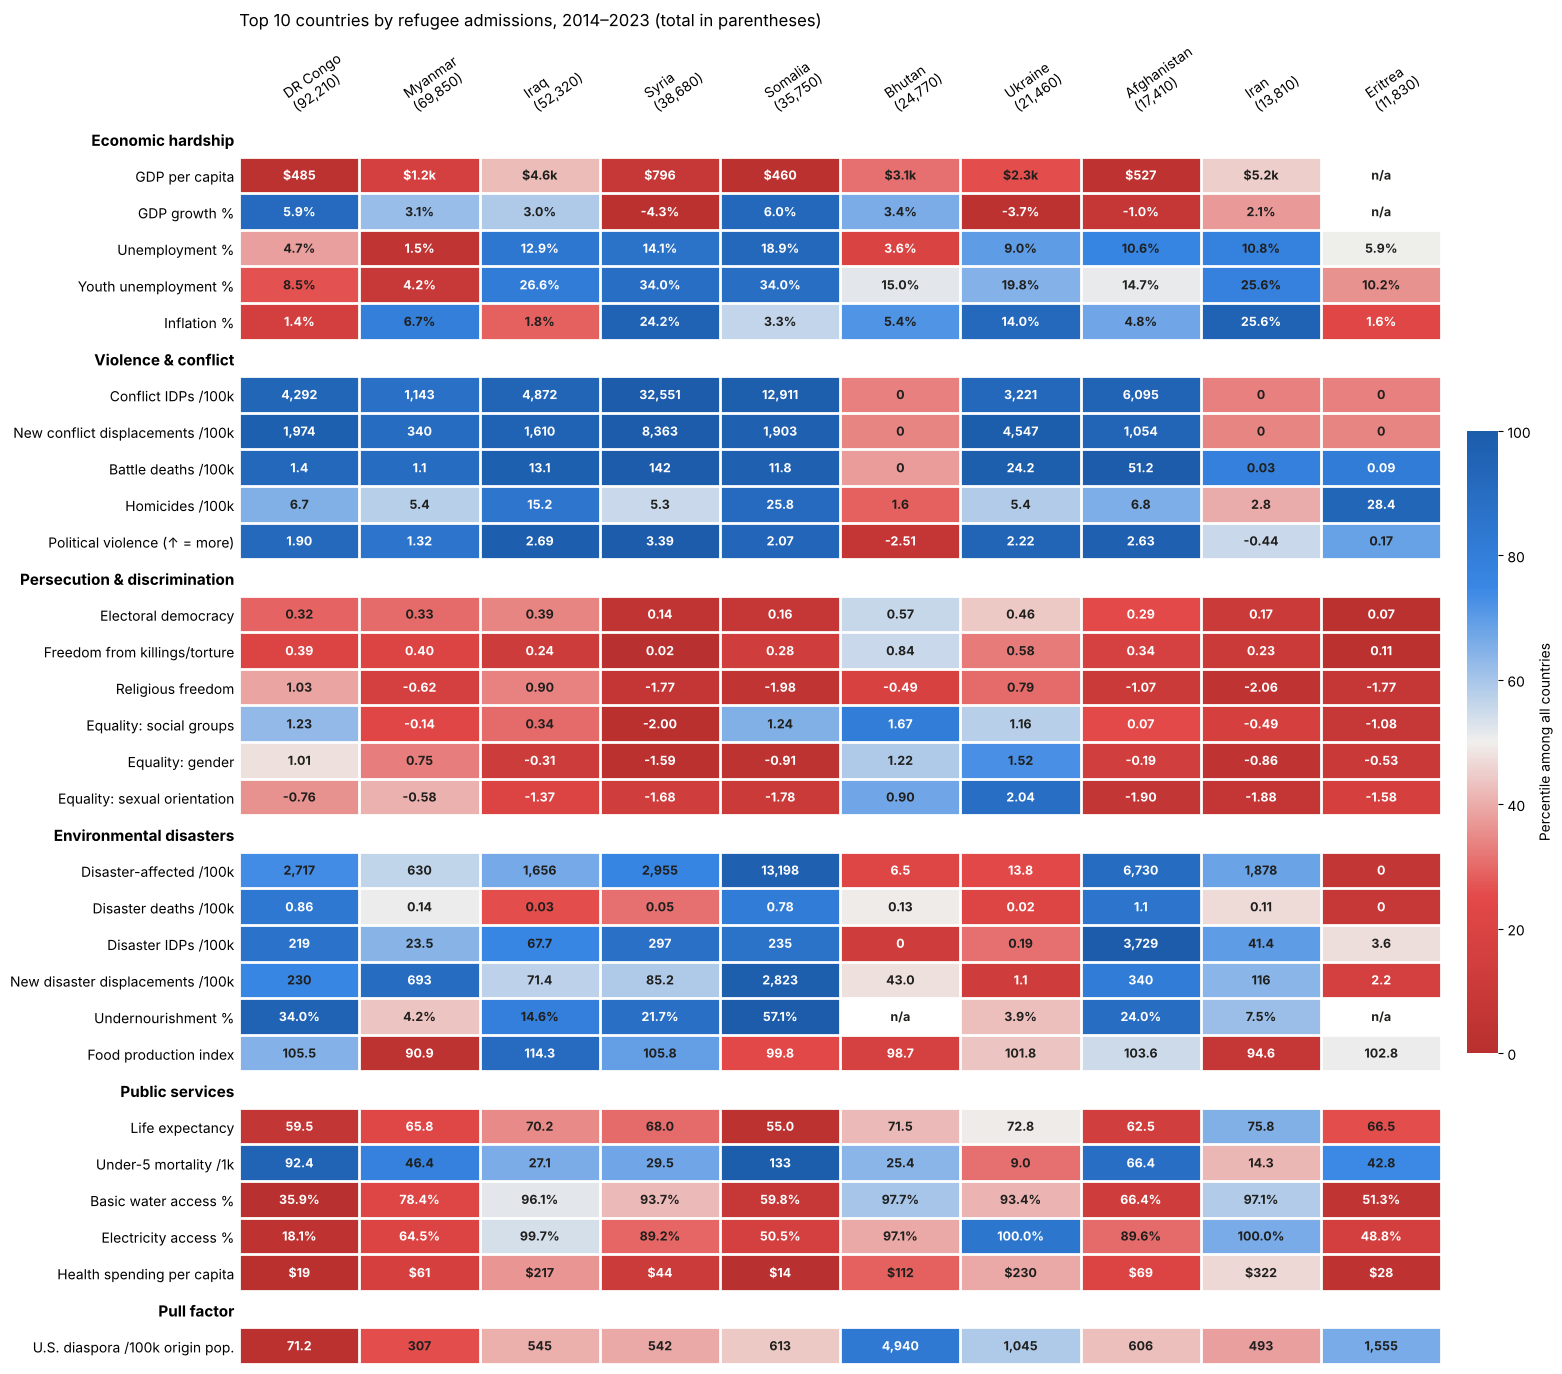

In [7]:
plot_top_senders("refugees", "refugee admissions", "normalized_top10_refugees.png", n=10)

## Apprehensions (top 5)

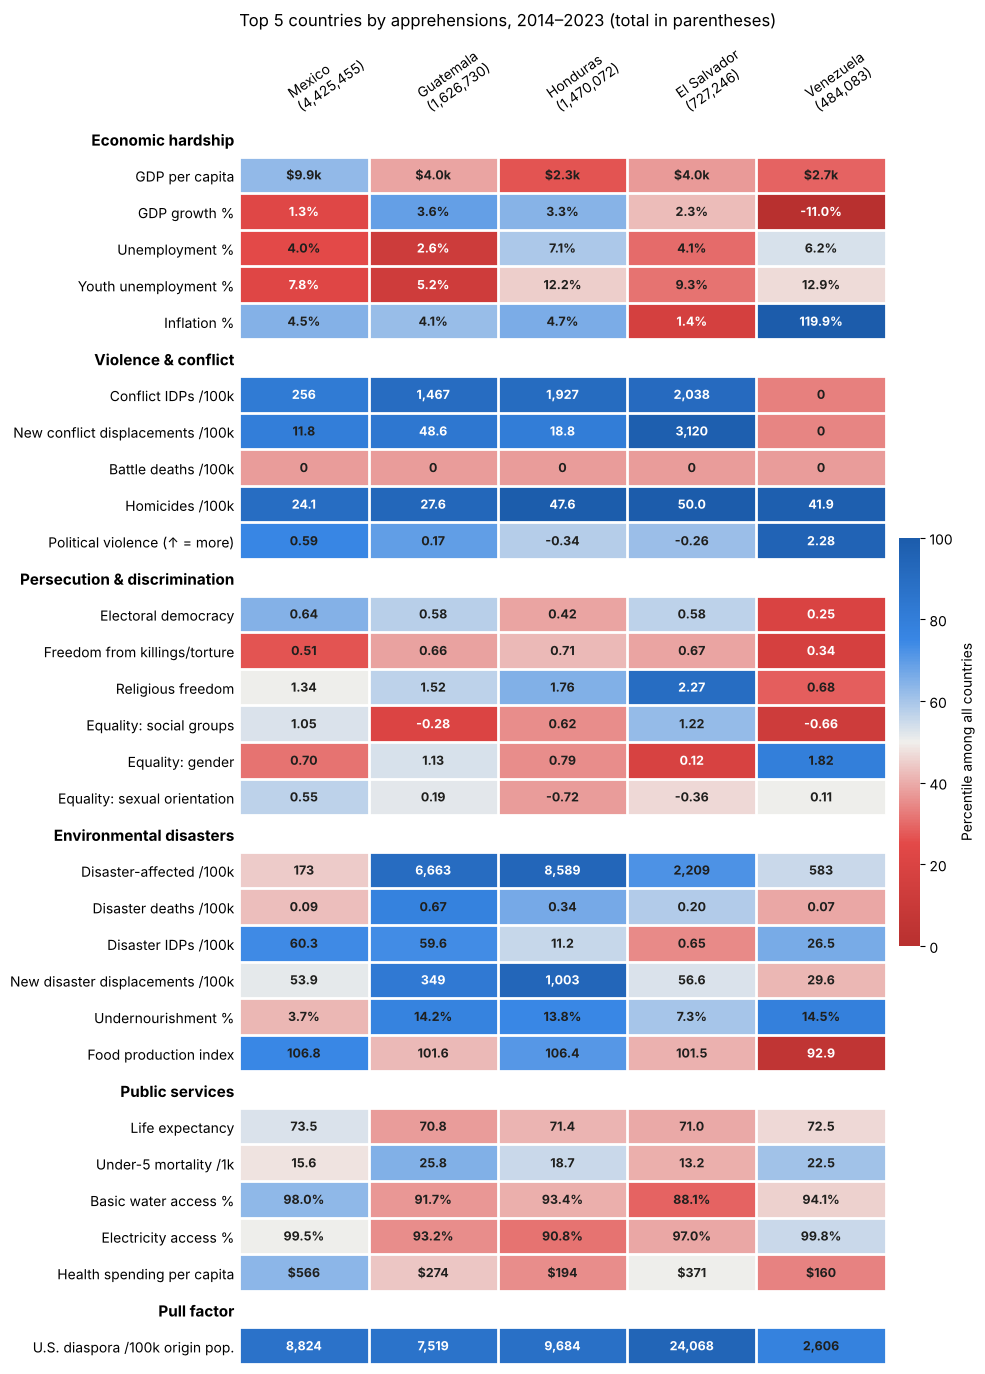

In [8]:
plot_top_senders("apprehensions", "apprehensions", "normalized_top5_apprehensions.png")

## Green cards, excluding refugee/asylee adjustments (top 5)

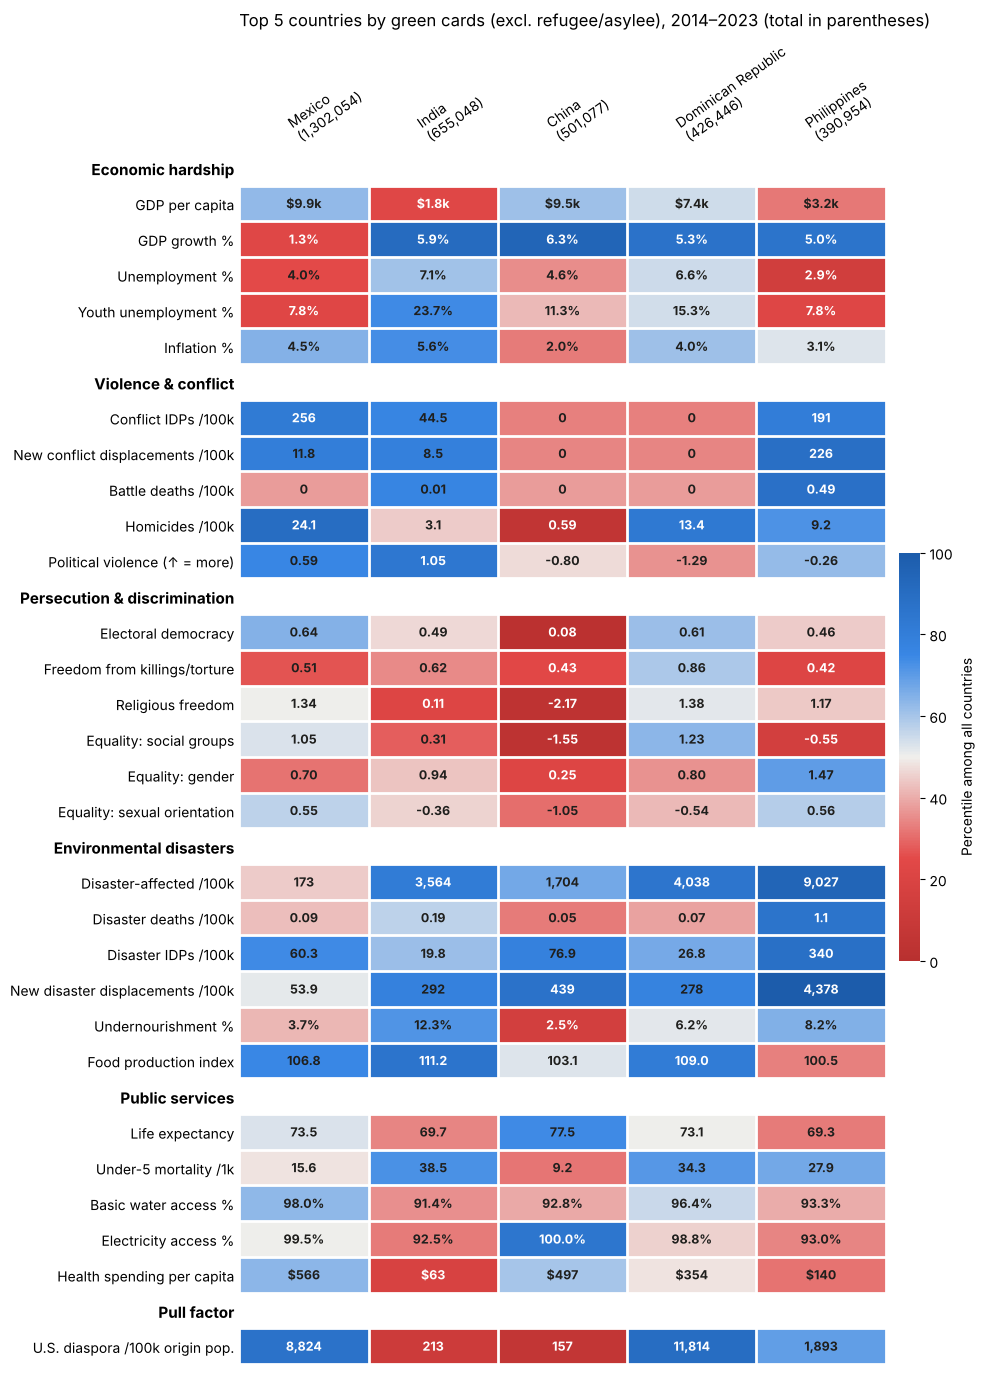

In [9]:
plot_top_senders("green_cards_excl_refugee_asylee", "green cards (excl. refugee/asylee)", "normalized_top5_green_cards.png")

## Asylum grants (top 5)

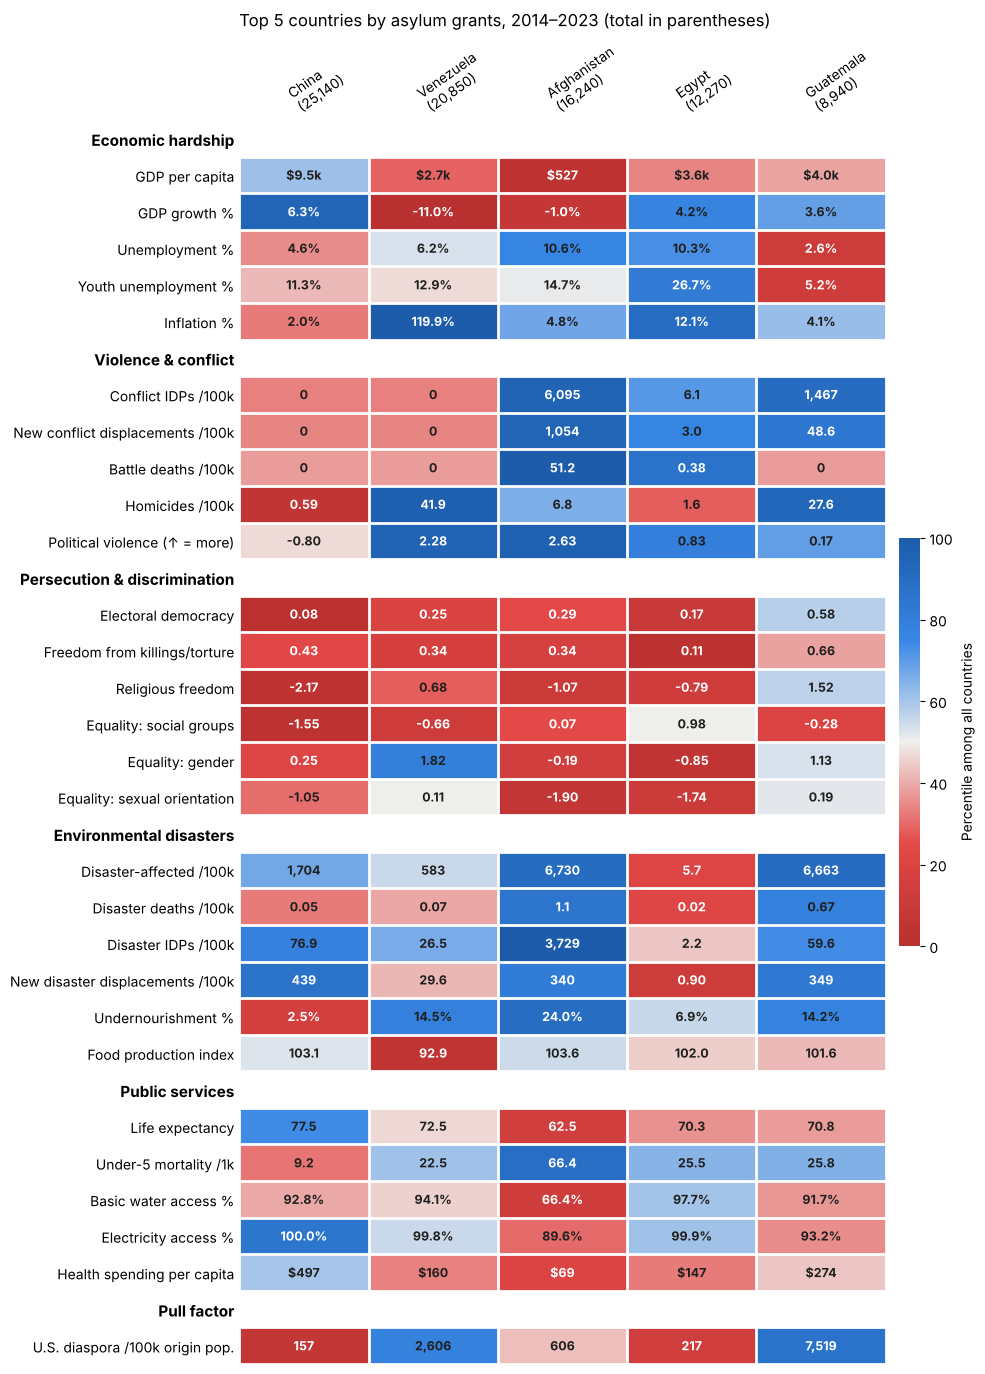

In [10]:
plot_top_senders("asylum_grants", "asylum grants", "normalized_top5_asylum.png")

---
# 3. Trends over time: top 10 countries for each immigration type

The 10 countries that sent the most people to the U.S. in total over 2014–2023, for each type.
One panel per country, all on the **same scale** within a chart: the highlighted line is that country,
the gray lines are the other nine for comparison. Dot = peak year.

In [11]:
ACCENT, CONTEXT, INK, MUTED = "#1c5cab", "#d3d1cc", "#1f1f1d", "#6b6a66"

def plot_trends(count_col, title, source, filename, n=10):
    data = counts.pivot(index="year", columns="country", values=count_col)
    top = data.sum().sort_values(ascending=False).head(n).index.tolist()
    years = data.index.values
    ymax = data[top].max().max() * 1.15

    fig, axes = plt.subplots(2, 5, figsize=(15, 6.4), sharex=True, sharey=True)
    for ax, country in zip(axes.flat, top):
        for other in top:
            if other != country:
                ax.plot(years, data[other], color=CONTEXT, linewidth=1.2, zorder=1)
        y = data[country]
        ax.plot(years, y, color=ACCENT, linewidth=2.4, zorder=3)
        peak = y.idxmax()
        ax.scatter([peak], [y[peak]], s=28, color=ACCENT, edgecolor="white", linewidth=1.5, zorder=4)
        ax.annotate(f"{y[peak]:,.0f}", (peak, y[peak]), xytext=(0, 7), textcoords="offset points",
                    ha="center", fontsize=9, color=INK)
        ax.set_title(country, fontsize=12, color=INK, loc="left", fontweight="bold", pad=16)
        ax.text(0, 1.02, f"{y.sum():,.0f} total", transform=ax.transAxes, fontsize=9, color=MUTED,
                va="bottom", ha="left")
        ax.set_ylim(0, ymax)
        ax.set_xlim(2013.4, 2023.6)
        ax.grid(axis="y", color="#ecebe7", linewidth=0.8)
        for side in ["top", "right", "left"]:
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color("#bdbbb5")
        ax.tick_params(colors=MUTED, labelsize=9, length=0)
        ax.set_xticks([2014, 2017, 2020, 2023])
        ax.tick_params(axis="x", labelbottom=True)   # years on every panel
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:g}k" if v else "0"))

    fig.suptitle(title, x=0.01, ha="left", fontsize=13, color=INK)
    fig.text(0.01, 0.005, f"Source: {source}. Dot = peak year.", fontsize=9, color=MUTED)
    plt.tight_layout(rect=(0, 0.03, 1, 0.95), h_pad=2.5)
    plt.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()
    return data[top].astype("Int64")

## Refugees

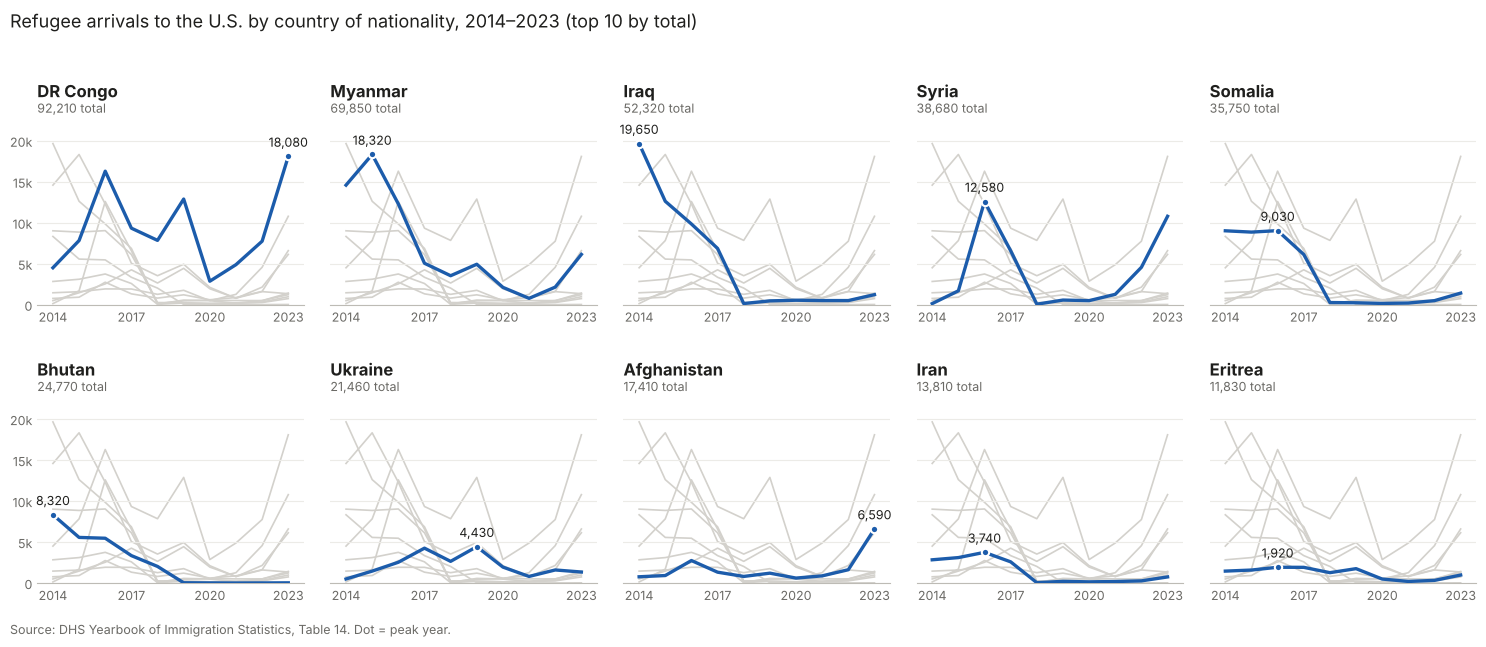

country,DR Congo,Myanmar,Iraq,Syria,Somalia,Bhutan,Ukraine,Afghanistan,Iran,Eritrea
year,,,,,,,,,,
2014,4500,14580,19650,130,9010,8320,490,760,2830,1450
2015,7820,18320,12610,1690,8850,5560,1450,910,3100,1580
2016,16280,12290,9840,12580,9030,5460,2530,2740,3740,1920
2017,9330,5050,6860,6570,6120,3340,4250,1320,2580,1910
2018,7840,3530,140,60,260,2020,2640,800,40,1260
2019,12880,4930,460,560,230,30,4430,1200,200,1750
2020,2860,2110,540,490,150,10,1940,600,140,480
2021,4880,770,500,1260,200,0,800,870,180,190
2022,7740,2140,500,4560,490,10,1590,1620,260,320


In [12]:
plot_trends("refugees",
            "Refugee arrivals to the U.S. by country of nationality, 2014–2023 (top 10 by total)",
            "DHS Yearbook of Immigration Statistics, Table 14", "top10_refugees_over_time.png")

## Apprehensions
FY2023 is Border Patrol apprehensions only and exists for 12 countries; other countries' 2023 values are blank.

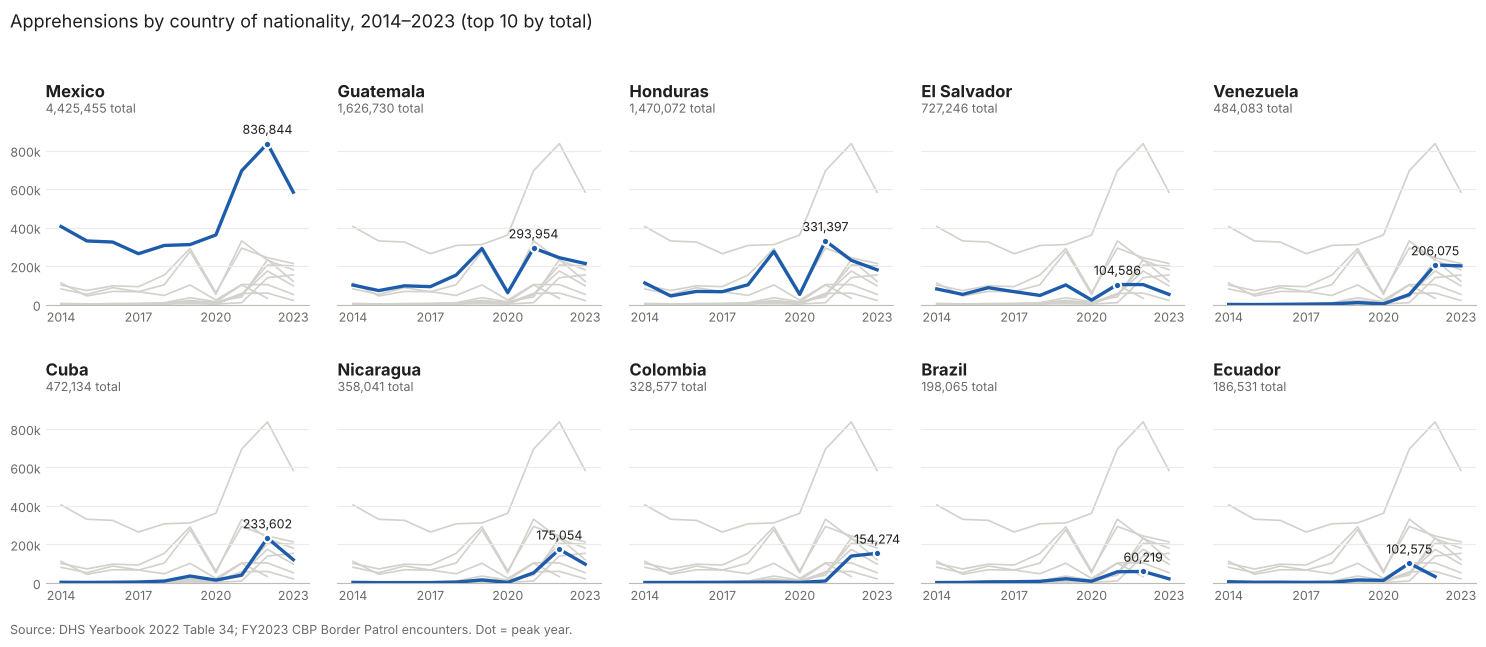

country,Mexico,Guatemala,Honduras,El Salvador,Venezuela,Cuba,Nicaragua,Colombia,Brazil,Ecuador
year,,,,,,,,,,
2014,405844,101695,112530,81651,640,3724,3228,2568,2353,6640
2015,330921,73111,45228,53336,683,3014,1900,2807,2877,3995
2016,325348,97967,68778,88097,1333,3739,2086,3256,6112,4222
2017,264716,93519,67225,67500,2383,5076,2005,3491,6643,3308
2018,307535,153814,103533,47993,4210,10065,4547,4066,8555,3277
2019,312130,292022,276805,102484,10465,36082,15641,4705,22198,15451
2020,362105,62848,52920,23887,4265,15048,3123,2970,9228,13808
2021,695582,293954,331397,104586,52590,40549,52633,10381,58151,102575
2022,836844,243913,230593,104261,206075,233602,175054,140059,60219,33255


In [13]:
plot_trends("apprehensions",
            "Apprehensions by country of nationality, 2014–2023 (top 10 by total)",
            "DHS Yearbook 2022 Table 34; FY2023 CBP Border Patrol encounters", "top10_apprehensions_over_time.png")

## Green cards (excluding refugee/asylee adjustments)
The line breaks at 2017 because DHS's class breakdown for FY2017 could not be read.

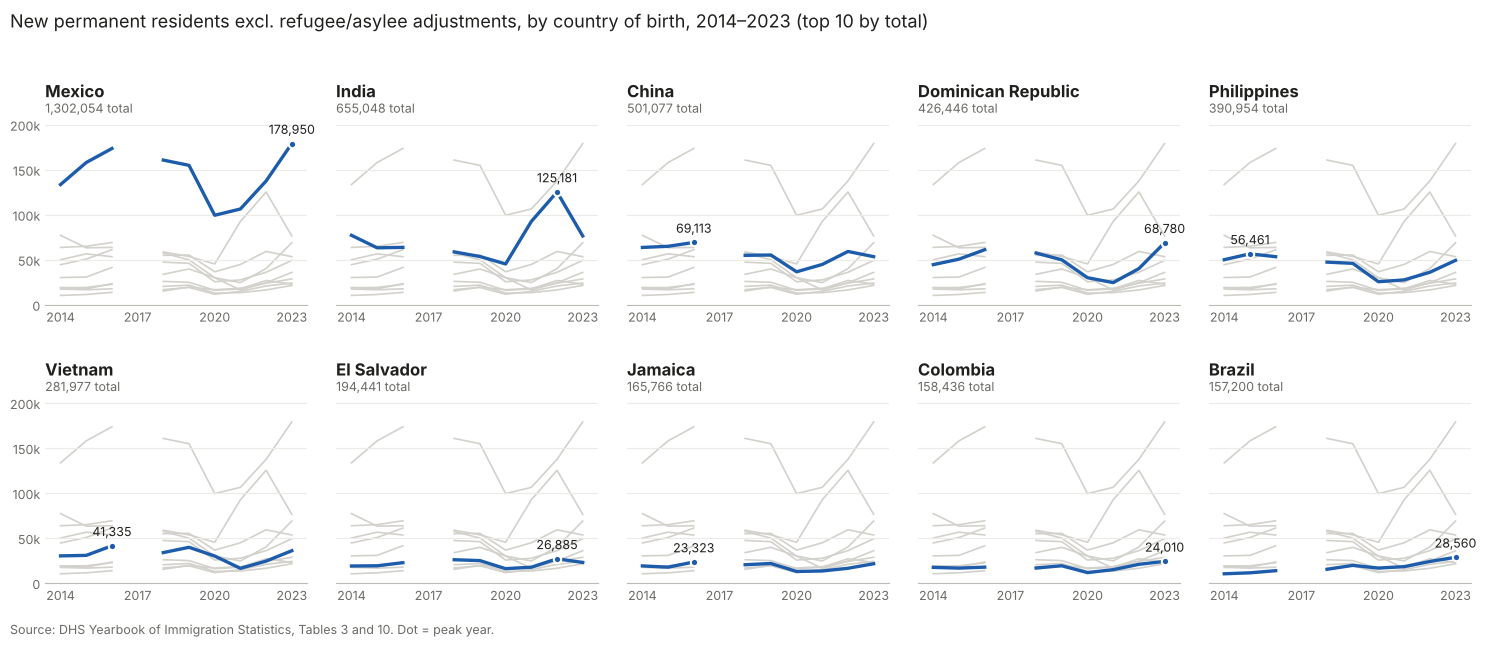

country,Mexico,India,China,Dominican Republic,Philippines,Vietnam,El Salvador,Jamaica,Colombia,Brazil
year,,,,,,,,,,
2014,133432,77033,63576,44469,49956,30125,18884,18986,17355,10250
2015,157894,63142,64833,50556,56461,30682,19124,17577,16535,11304
2016,173488,63622,69113,61049,53273,41335,22553,23323,17602,13658
2017,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2018,160590,58592,54790,57313,47237,33772,25850,20307,16704,15205
2019,154747,53493,55169,49795,45903,39646,24875,21674,19136,19582
2020,99304,45214,36524,29949,25481,29936,15904,12819,11542,16600
2021,106271,92441,44663,24494,27498,16290,17546,13346,14815,18172
2022,137378,125181,59089,40041,35965,24341,26885,16354,20737,23869


In [14]:
plot_trends("green_cards_excl_refugee_asylee",
            "New permanent residents excl. refugee/asylee adjustments, by country of birth, 2014–2023 (top 10 by total)",
            "DHS Yearbook of Immigration Statistics, Tables 3 and 10", "top10_green_cards_over_time.png")

## Asylum grants
Affirmative asylum grants only (people who applied to USCIS), not asylum granted by immigration judges.

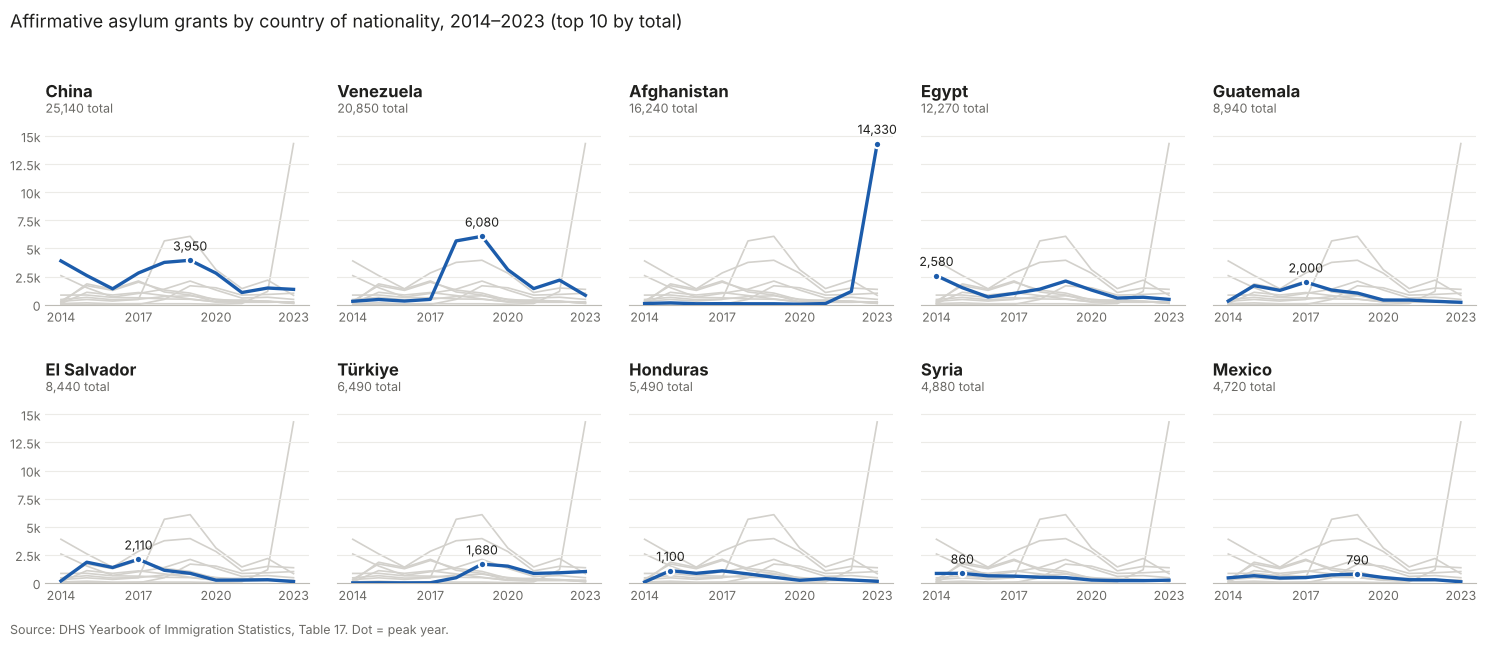

country,China,Venezuela,Afghanistan,Egypt,Guatemala,El Salvador,Türkiye,Honduras,Syria,Mexico
year,,,,,,,,,,
2014,3890,300,100,2580,320,180,10,90,850,460
2015,2590,460,160,1510,1690,1850,20,1100,860,650
2016,1410,320,80,680,1270,1380,10,860,640,440
2017,2820,470,90,1000,2000,2110,20,1080,610,480
2018,3760,5670,80,1380,1300,1130,470,810,510,720
2019,3950,6080,80,2100,1030,860,1680,510,480,790
2020,2800,3110,40,1300,410,250,1500,240,260,490
2021,1080,1430,100,590,410,260,850,380,210,290
2022,1480,2180,1180,660,300,290,910,270,210,290


In [15]:
plot_trends("asylum_grants",
            "Affirmative asylum grants by country of nationality, 2014–2023 (top 10 by total)",
            "DHS Yearbook of Immigration Statistics, Table 17", "top10_asylum_over_time.png")

---
# 4. Conflict displacement vs. U.S. immigration (scatter)

One dot per country, using its **2014–2023 average**. x = people internally displaced by conflict per 100k (previous year);
y = each immigration type per 100k. Both axes are **log scales**; countries with a value of exactly 0 sit in the
**"0" strip** past the dashed line so they stay visible. ρ = Spearman rank correlation across countries (zeros included).
The trend line is fit only to countries with nonzero values on both axes.

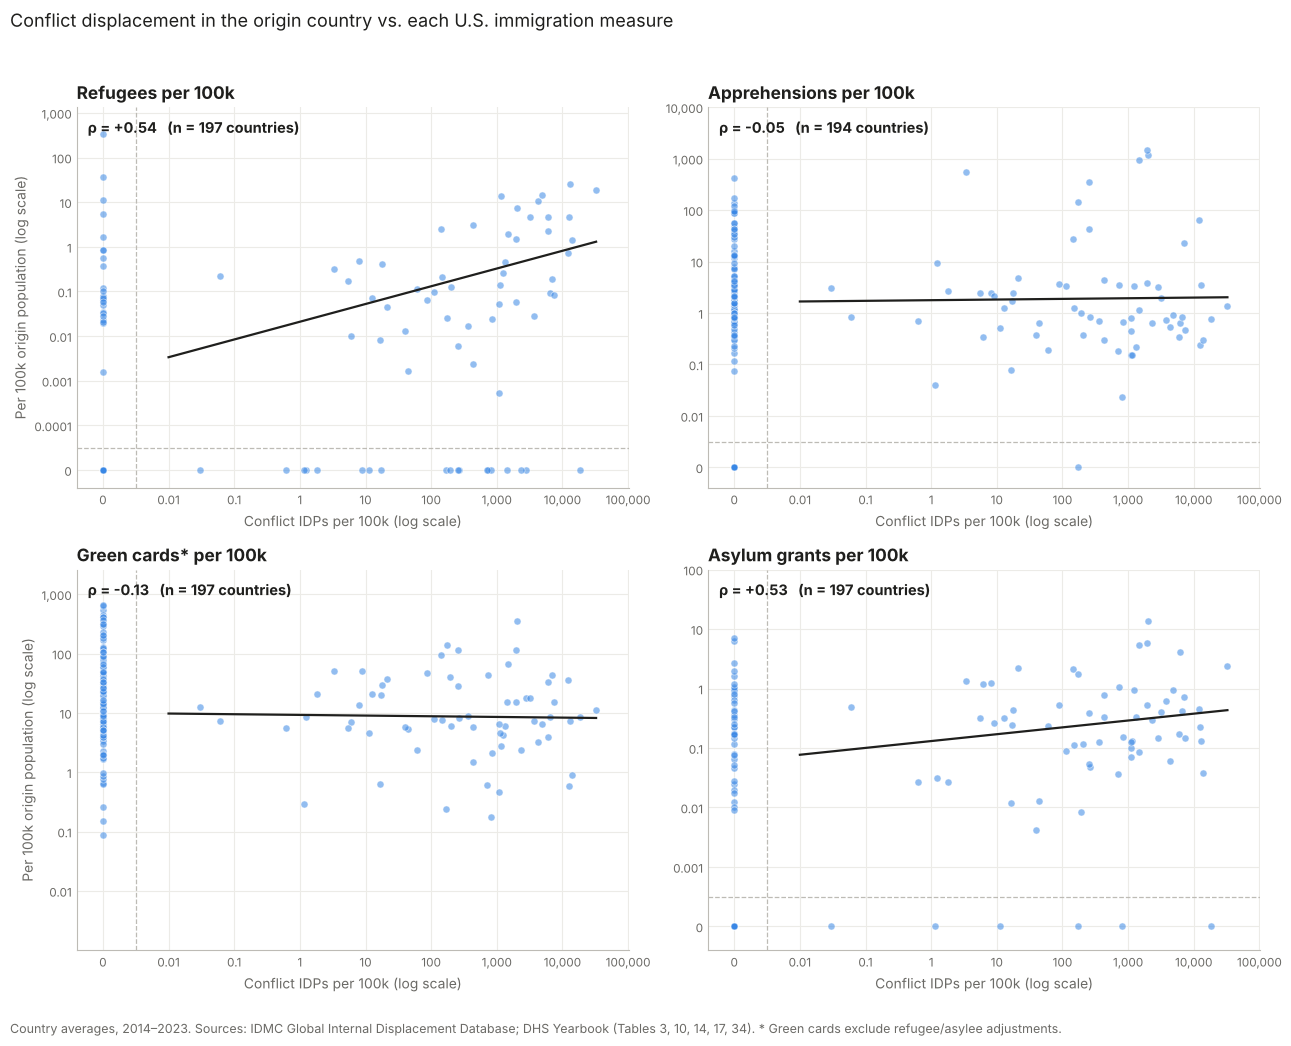

In [16]:
X = "idps_conflict_per_100k_lag1"
avg = df.groupby("country")[[X] + list(outcomes)].mean()

DOT = "#3987e5"

def to_axis(v, zero_pos):
    v = np.asarray(v, float)
    out = np.full(v.shape, np.nan)
    out[v > 0] = np.log10(v[v > 0])
    out[v == 0] = zero_pos
    return out

def log_ticks(ax, which, lo, hi, zero_pos):
    decades = np.arange(int(np.floor(lo)), int(np.ceil(hi)) + 1)
    pos = [zero_pos] + list(decades)
    labels = ["0"] + [f"{10.0**d:,.0f}" if d >= 0 else f"{10.0**d:g}" for d in decades]
    (ax.set_xticks if which == "x" else ax.set_yticks)(pos, labels)

xs = avg[X]
x_lo, x_hi = np.log10(xs[xs > 0].min()), np.log10(xs.max())
x_zero = np.floor(x_lo) - 1.0

fig, axes = plt.subplots(2, 2, figsize=(13, 10.5))
axes = axes.flat
for ax, (ycol, ylabel) in zip(axes, outcomes.items()):
    d = avg[[X, ycol]].dropna()
    ys = d[ycol]
    y_lo, y_hi = np.log10(ys[ys > 0].min()), np.log10(ys.max())
    y_zero = np.floor(y_lo) - 1.0
    px, py = to_axis(d[X], x_zero), to_axis(ys, y_zero)

    ax.scatter(px, py, s=26, color=DOT, alpha=0.55, edgecolor="white", linewidth=0.6, zorder=3)

    # trend line on countries nonzero on both axes
    nz = (d[X] > 0) & (ys > 0)
    b, a = np.polyfit(np.log10(d.loc[nz, X]), np.log10(ys[nz]), 1)
    xx = np.linspace(np.floor(x_lo), x_hi, 50)
    ax.plot(xx, a + b * xx, color=INK, linewidth=1.6, zorder=4)

    rho_c = spearmanr(d[X], ys)[0]
    ax.text(0.02, 0.97, f"ρ = {rho_c:+.2f}   (n = {len(d)} countries)", transform=ax.transAxes,
            va="top", fontsize=10.5, color=INK, fontweight="bold")


    # zero strips (only drawn when that axis actually has zeros)
    ax.axvline(x_zero + 0.5, color="#bdbbb5", linestyle="--", linewidth=0.9)
    ax.set_xlim(x_zero - 0.4, x_hi + 0.5)
    log_ticks(ax, "x", np.floor(x_lo), x_hi, x_zero)
    if (ys == 0).any():
        ax.axhline(y_zero + 0.5, color="#bdbbb5", linestyle="--", linewidth=0.9)
        ax.set_ylim(y_zero - 0.4, y_hi + 0.6)
        log_ticks(ax, "y", np.floor(y_lo), y_hi, y_zero)
    else:
        ax.set_ylim(np.floor(y_lo) - 0.3, y_hi + 0.6)
        log_ticks(ax, "y", np.floor(y_lo), y_hi, y_zero)
        ax.set_yticks(ax.get_yticks()[1:], [t.get_text() for t in ax.get_yticklabels()][1:])

    ax.set_title(f"{ylabel} per 100k", fontsize=12.5, color=INK, loc="left", fontweight="bold")
    ax.set_xlabel("Conflict IDPs per 100k (log scale)", fontsize=10, color=MUTED)
    ax.grid(color="#ecebe7", linewidth=0.8, zorder=0)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color("#bdbbb5")
    ax.tick_params(colors=MUTED, labelsize=8.5, length=0)

for a_ in (axes[0], axes[2]):
    a_.set_ylabel("Per 100k origin population (log scale)", fontsize=10, color=MUTED)
fig.suptitle("Conflict displacement in the origin country vs. each U.S. immigration measure",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.text(0.01, 0.005, "Country averages, 2014–2023. Sources: IDMC Global Internal Displacement Database; "
         "DHS Yearbook (Tables 3, 10, 14, 17, 34). * Green cards exclude refugee/asylee adjustments.", fontsize=9, color=MUTED)
plt.tight_layout(rect=(0, 0.03, 1, 0.96))
plt.savefig("idps_vs_immigration_scatter.png", dpi=200, bbox_inches="tight")
plt.show()

---
# 5. Top 30 countries per 100k, by immigration type

Each country's **average per-100k rate over 2014–2023** (average of its yearly values). Per-capita rankings favor
small countries: a few hundred people from a nation of 100,000 is a high rate.

In [17]:
def plot_top30_rate(col, title, source, filename, n=30):
    avg_rate = df.groupby("country")[col].mean().dropna().sort_values(ascending=False).head(n)[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.3 * n + 1.6))
    ax.barh(avg_rate.index, avg_rate.values, color=ACCENT, height=0.72, zorder=3)
    xmax = avg_rate.max()
    for y, v in enumerate(avg_rate.values):
        ax.text(v + xmax * 0.01, y, f"{v:,.1f}" if v < 100 else f"{v:,.0f}", va="center", fontsize=9, color=INK)
    ax.set_xlim(0, xmax * 1.12)
    ax.set_ylim(-0.6, n - 0.4)
    ax.grid(axis="x", color="#ecebe7", linewidth=0.8, zorder=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#bdbbb5")
    ax.tick_params(axis="y", length=0, labelsize=10, colors=INK)
    ax.tick_params(axis="x", length=0, labelsize=9, colors=MUTED)
    ax.set_xlabel("Average per 100k origin population per year, 2014–2023", fontsize=10, color=MUTED)
    ax.set_title(title, fontsize=13, color=INK, loc="left", pad=12)
    fig.text(0.01, 0.005, f"Source: {source}; population from World Bank WDI.", fontsize=9, color=MUTED)
    plt.tight_layout(rect=(0, 0.02, 1, 1))
    plt.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()
    return avg_rate[::-1].round(1)

## Apprehensions

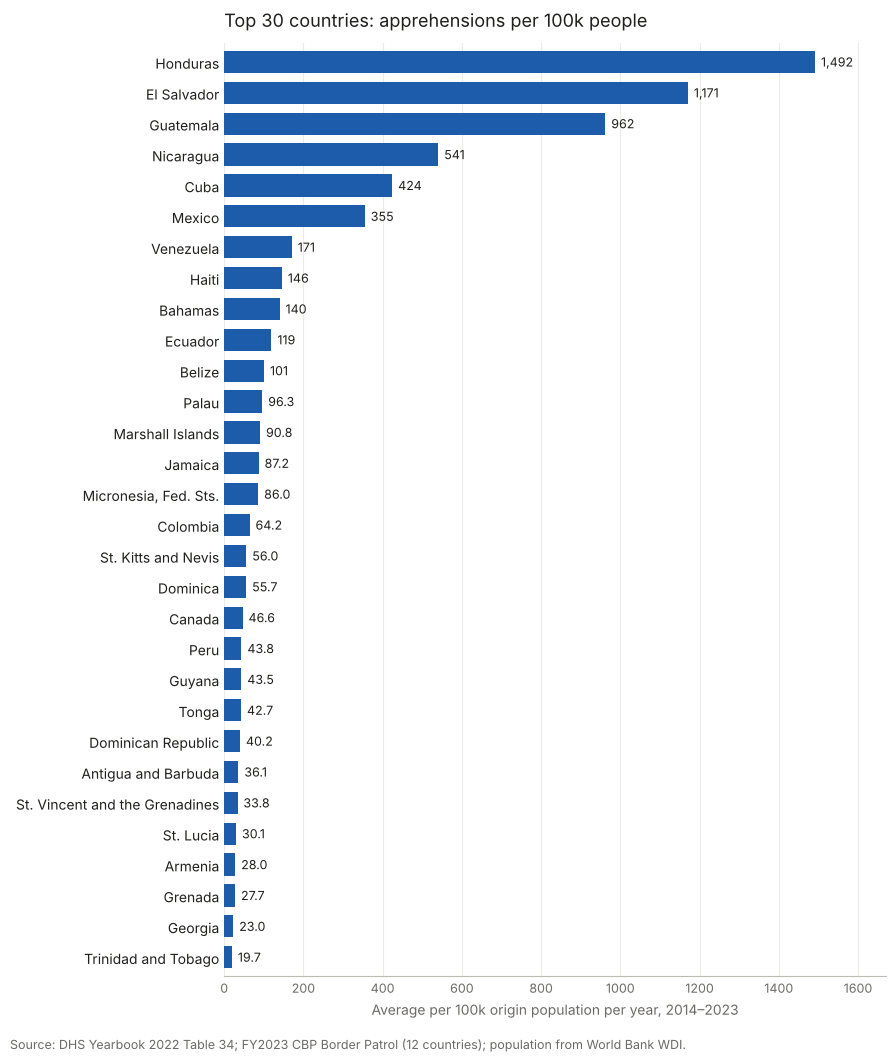

country
Honduras                          1491.6
El Salvador                       1170.8
Guatemala                          962.3
Nicaragua                          540.5
Cuba                               424.2
Mexico                             355.1
Venezuela                          170.9
Haiti                              145.8
Bahamas                            140.1
Ecuador                            119.5
Belize                             100.8
Palau                               96.3
Marshall Islands                    90.8
Jamaica                             87.2
Micronesia, Fed. Sts.               86.0
Colombia                            64.2
St. Kitts and Nevis                 56.0
Dominica                            55.7
Canada                              46.6
Peru                                43.8
Guyana                              43.5
Tonga                               42.7
Dominican Republic                  40.2
Antigua and Barbuda                 36.1
St. Vinc

In [18]:
plot_top30_rate("apprehensions_per_100k", "Top 30 countries: apprehensions per 100k people",
                "DHS Yearbook 2022 Table 34; FY2023 CBP Border Patrol (12 countries)", "top30_apprehensions_per_100k.png")

## Green cards (excluding refugee/asylee adjustments)

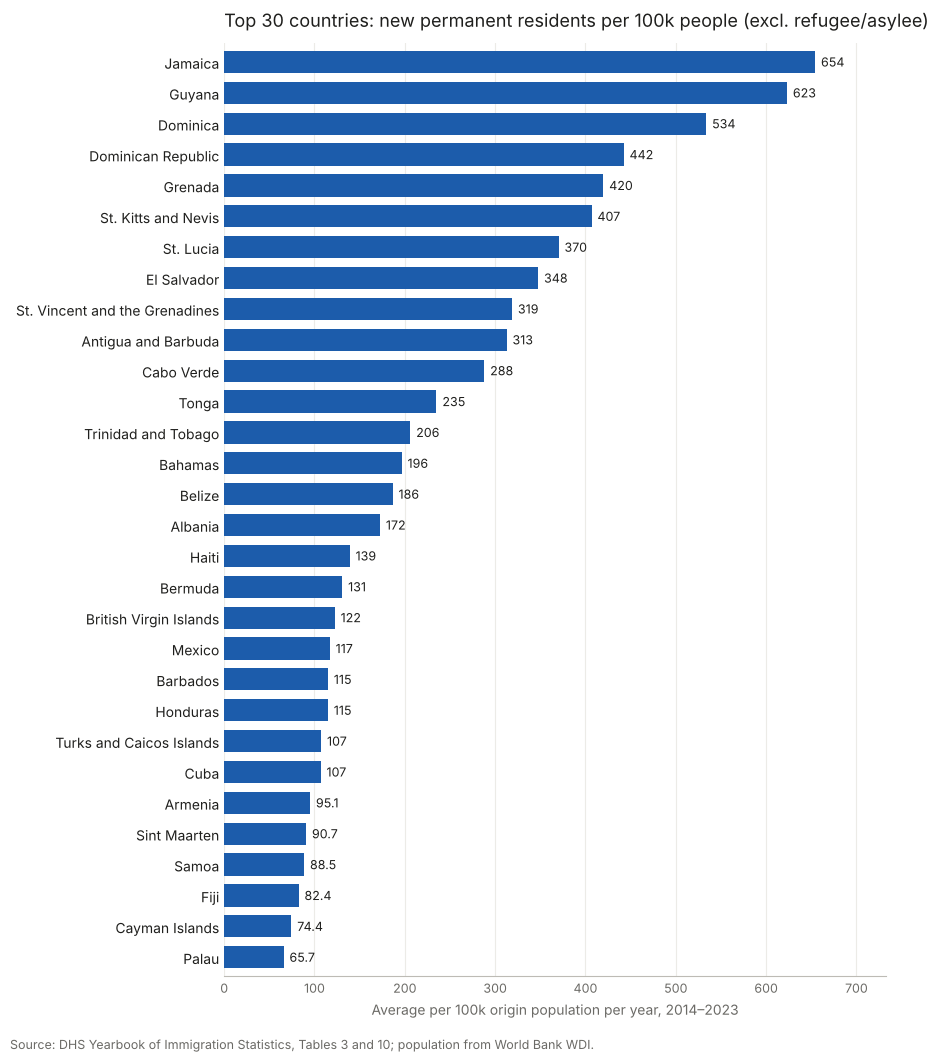

country
Jamaica                           654.2
Guyana                            623.1
Dominica                          533.7
Dominican Republic                442.3
Grenada                           419.7
St. Kitts and Nevis               406.7
St. Lucia                         370.3
El Salvador                       347.6
St. Vincent and the Grenadines    318.7
Antigua and Barbuda               312.7
Cabo Verde                        287.9
Tonga                             235.1
Trinidad and Tobago               206.0
Bahamas                           196.5
Belize                            186.5
Albania                           172.5
Haiti                             139.0
Bermuda                           130.7
British Virgin Islands            122.4
Mexico                            116.9
Barbados                          114.9
Honduras                          114.8
Turks and Caicos Islands          107.3
Cuba                              106.8
Armenia                         

In [19]:
plot_top30_rate("green_cards_excl_refugee_asylee_per_100k", "Top 30 countries: new permanent residents per 100k people (excl. refugee/asylee)",
                "DHS Yearbook of Immigration Statistics, Tables 3 and 10", "top30_green_cards_per_100k.png")

## Refugees

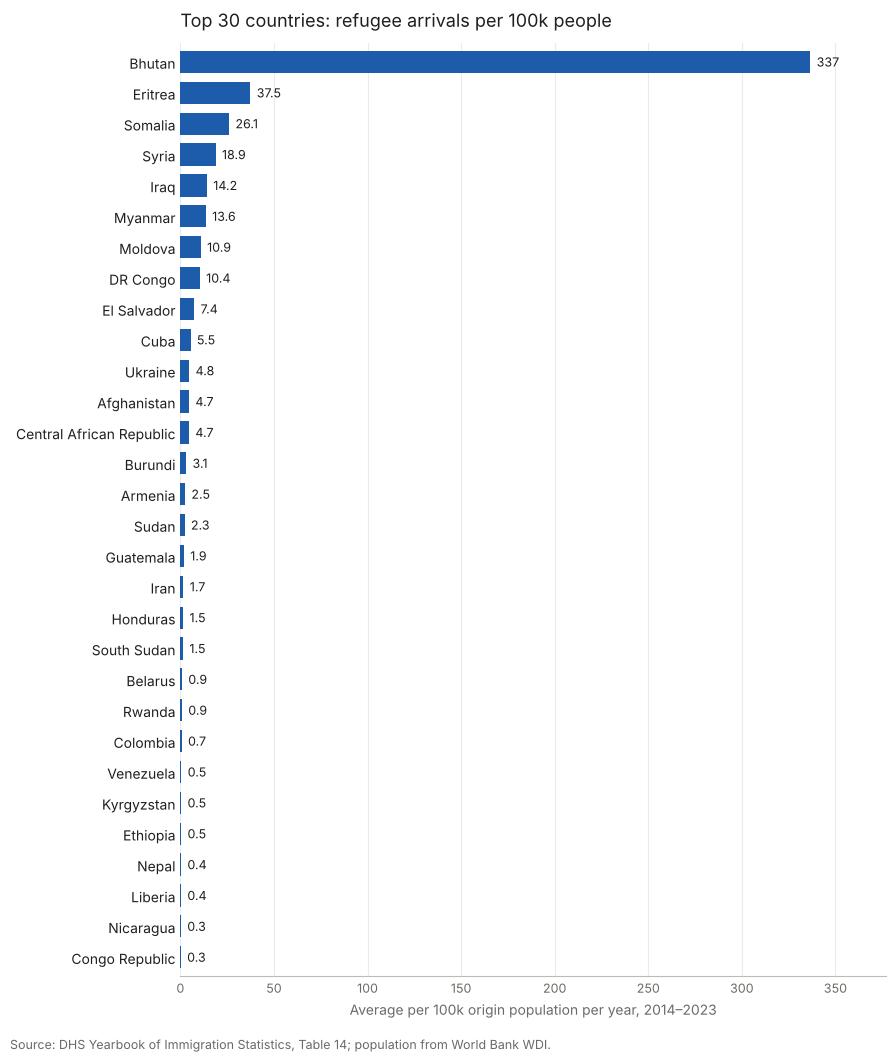

country
Bhutan                      336.6
Eritrea                      37.5
Somalia                      26.1
Syria                        18.9
Iraq                         14.2
Myanmar                      13.6
Moldova                      10.9
DR Congo                     10.4
El Salvador                   7.4
Cuba                          5.5
Ukraine                       4.8
Afghanistan                   4.7
Central African Republic      4.7
Burundi                       3.1
Armenia                       2.5
Sudan                         2.3
Guatemala                     1.9
Iran                          1.7
Honduras                      1.5
South Sudan                   1.5
Belarus                       0.9
Rwanda                        0.9
Colombia                      0.7
Venezuela                     0.5
Kyrgyzstan                    0.5
Ethiopia                      0.5
Nepal                         0.4
Liberia                       0.4
Nicaragua                     0.3
Congo 

In [20]:
plot_top30_rate("refugees_per_100k", "Top 30 countries: refugee arrivals per 100k people",
                "DHS Yearbook of Immigration Statistics, Table 14", "top30_refugees_per_100k.png")

## Asylum grants

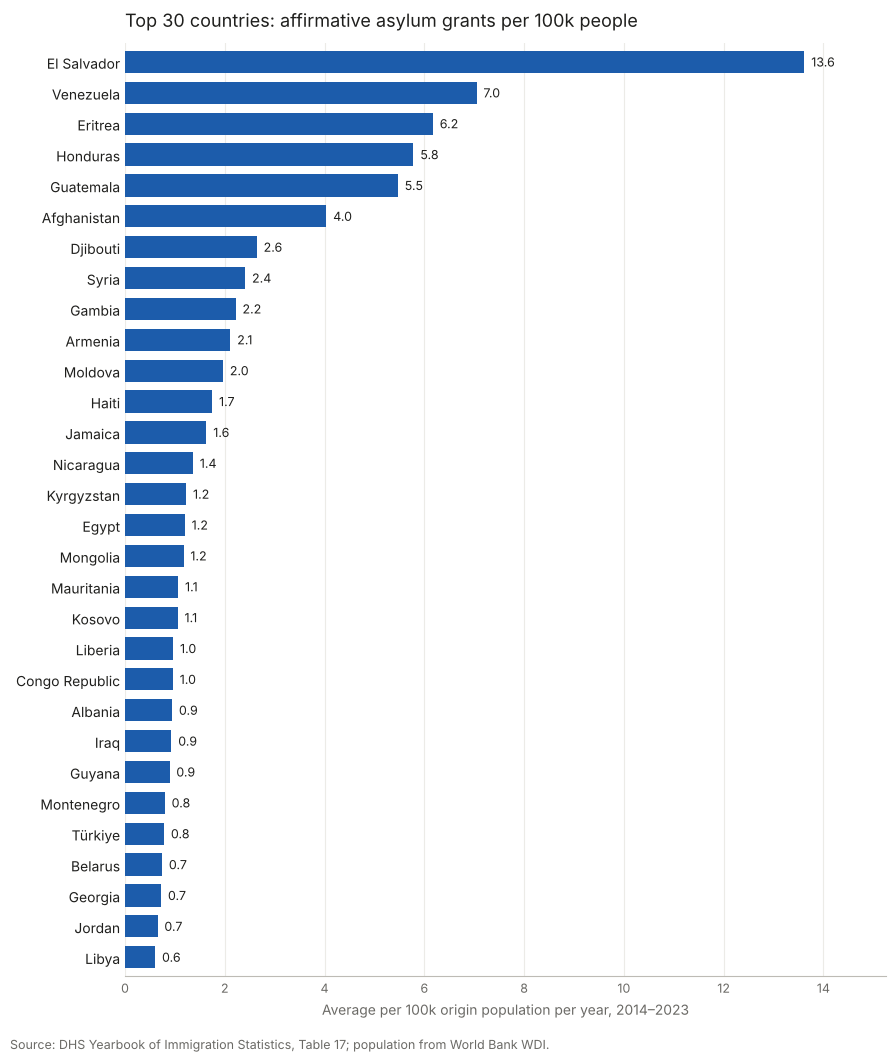

country
El Salvador       13.6
Venezuela          7.0
Eritrea            6.2
Honduras           5.8
Guatemala          5.5
Afghanistan        4.0
Djibouti           2.6
Syria              2.4
Gambia             2.2
Armenia            2.1
Moldova            2.0
Haiti              1.7
Jamaica            1.6
Nicaragua          1.4
Kyrgyzstan         1.2
Egypt              1.2
Mongolia           1.2
Mauritania         1.1
Kosovo             1.1
Liberia            1.0
Congo Republic     1.0
Albania            0.9
Iraq               0.9
Guyana             0.9
Montenegro         0.8
Türkiye            0.8
Belarus            0.7
Georgia            0.7
Jordan             0.7
Libya              0.6
Name: asylum_grants_per_100k, dtype: float64

In [21]:
plot_top30_rate("asylum_grants_per_100k", "Top 30 countries: affirmative asylum grants per 100k people",
                "DHS Yearbook of Immigration Statistics, Table 17", "top30_asylum_per_100k.png")

---
# 6. Case studies: Bhutan (refugees), Jamaica (green cards), El Salvador (asylum)

Each case country is the highest per-capita sender for its immigration type. The top panel tracks the **number** of
people it sent each year; the panels below track the indicators most strongly correlated with that immigration type.

**How variables are chosen (from the correlation heatmap in section 1):**
- With ~2,000 country-years, every correlation above ±0.2 is statistically significant (p < 10⁻¹²), so significance alone
  doesn't separate strong from weak relationships. Instead a variable counts as **strongly associated if |ρ| ≥ 0.40**
  (moderate or stronger).
- Excluded from the time panels: **U.S. diaspora** (one 2023 value per country, so it can't change over time) and
  **total and disaster IDPs** (only measured from 2019, so too few years to show a trend).
- **Only strong indicators are shown.** If an outcome has no time-varying variable with |ρ| ≥ 0.40 (the printout below
  says which), its chart shows the outcome alone with the country's diaspora figure noted.
- Jamaica uses green cards **excluding refugee/asylee adjustments** (Jamaica has almost none, so the line barely changes);
  2017 is blank.
- Indicators are plotted at the **calendar year they describe** (the year before the immigration figure they're paired with),
  so 2013–2022 for indicators vs 2014–2023 for immigration.

In [22]:
THRESH = 0.40
STATIC = {"diaspora_in_us_per_100k_origin_pop", "idps_total_per_100k_lag1", "idps_disaster_per_100k_lag1"}
out_keys = list(outcomes)            # order matches rho[col] lists

def pick_vars(outcome_col):
    j = out_keys.index(outcome_col)
    r = pd.Series({c: rho[c][j] for c in indicators if c not in STATIC})
    strong = r[r.abs() >= THRESH].sort_values(key=abs, ascending=False)
    return strong, ("strong" if len(strong) else "none")

sel = {}
for o, name in outcomes.items():
    s, kind = pick_vars(o)
    sel[o] = (s, kind)
    print(f"\n{name}: " + ("strong associations" if len(s) else "no time-varying indicator with |ρ| ≥ 0.40"))
    if len(s):
        print(s.rename(index=indicators).round(2).to_string())
print("\nDiaspora (static, not plotted):", {outcomes[o]: round(rho['diaspora_in_us_per_100k_origin_pop'][j], 2) for j, o in enumerate(out_keys)})


Refugees: strong associations
Freedom from killings/torture      -0.49
Conflict IDPs /100k                 0.47
GDP per capita                     -0.44
New conflict displacements /100k    0.44
Health spending per capita         -0.43

Apprehensions: no time-varying indicator with |ρ| ≥ 0.40

Green cards*: no time-varying indicator with |ρ| ≥ 0.40

Asylum grants: strong associations
Freedom from killings/torture   -0.54
GDP per capita                  -0.52
Health spending per capita      -0.50
Electoral democracy             -0.46
Equality: sexual orientation    -0.45
Political violence (↑ = more)    0.45
Conflict IDPs /100k              0.44
Basic water access %            -0.42

Diaspora (static, not plotted): {'Refugees': np.float64(-0.15), 'Apprehensions': np.float64(0.82), 'Green cards*': np.float64(0.85), 'Asylum grants': np.float64(-0.07)}


In [23]:
IND_COLOR = "#4a4945"

def plot_case(country, outcome_col, count_col, count_label, filename, source):
    s, kind = sel[outcome_col]
    n = len(s)
    ncols = 3
    nrows = int(np.ceil(n / ncols))
    if n:
        fig = plt.figure(figsize=(14, 3.1 + 2.15 * nrows))
        gs = fig.add_gridspec(nrows + 1, ncols, height_ratios=[1.35] + [1] * nrows, hspace=0.75, wspace=0.28)

    cdata = counts[counts.country == country].set_index("year").sort_index()
    idata = df[df.country == country].set_index("year").sort_index()
    yrs = cdata.index.values

    if n:
        ax0 = fig.add_subplot(gs[0, :])
    else:
        fig, ax0 = plt.subplots(figsize=(14, 4.6))
    y = cdata[count_col]
    ax0.plot(yrs, y, color=ACCENT, linewidth=2.8, marker="o", markersize=5, zorder=3)
    for x_, v in zip(yrs, y):
        if not np.isnan(v):
            ax0.annotate(f"{v:,.0f}", (x_, v), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9, color=INK)
    ax0.set_title(f"{count_label} from {country}, by year", fontsize=12.5, color=INK, loc="left", fontweight="bold")
    ax0.set_ylim(0, y.max() * 1.22)
    ax0.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))

    axes = [ax0]
    for i, (col, r) in enumerate(s.items()):
        ax = fig.add_subplot(gs[1 + i // ncols, i % ncols])
        v = idata[col]
        ax.plot(yrs - 1, v.values, color=IND_COLOR, linewidth=2, marker="o", markersize=3.5, zorder=3)
        lo, hi = np.nanmin(v.values) if v.notna().any() else 0, np.nanmax(v.values) if v.notna().any() else 1
        pad = (hi - lo) * 0.25 if hi > lo else (abs(hi) * 0.1 or 1)
        ax.set_ylim(lo - pad, hi + pad)
        ax.set_title(indicators[col], fontsize=10.5, color=INK, loc="left", fontweight="bold", pad=14)
        ax.text(0, 1.02, f"ρ = {r:+.2f} with {outcomes[outcome_col].lower()}", transform=ax.transAxes,
                fontsize=8.5, color=MUTED, va="bottom")
        if v.isna().all():
            ax.text(0.5, 0.5, "no data", transform=ax.transAxes, ha="center", va="center", color=MUTED)
        axes.append(ax)

    for ax in axes:
        ax.set_xlim(2012.5 if n else 2013.5, 2023.5)
        ax.set_xticks(range(2013, 2024, 2) if ax is not ax0 else range(2014, 2024))
        ax.grid(axis="y", color="#ecebe7", linewidth=0.8, zorder=0)
        for side in ["top", "right", "left"]:
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color("#bdbbb5")
        ax.tick_params(colors=MUTED, labelsize=8.5, length=0)

    if n == 0:
        dcol = "diaspora_in_us_per_100k_origin_pop"
        dval = idata[dcol].dropna()
        dpct = df.groupby("country")[dcol].mean().rank(pct=True).get(country, np.nan) * 100
        j = out_keys.index(outcome_col)
        note = (f"No time-varying indicator reaches |ρ| ≥ 0.40 for {outcomes[outcome_col].lower()}. The only strong one is the U.S. diaspora "
                f"(ρ = {rho[dcol][j]:+.2f}), a single 2023 value: " +
                (f"{country}'s U.S. diaspora equals {dval.iloc[0]:,.0f} per 100k of its population ({dpct:.0f}th percentile)." if len(dval) else "no value for this country."))
        ax0.set_title(f"{count_label} from {country}, by year", fontsize=12.5, color=INK, loc="left", fontweight="bold", pad=34)
        ax0.text(0, 1.04, note.replace("population (", "population\n("), transform=ax0.transAxes, fontsize=9.5, color=MUTED, va="bottom")
        ax0.set_xlim(2013.5, 2023.5)
        head = "(no time-varying indicator reaches |ρ| ≥ 0.40)"
    else:
        head = "and the most strongly associated indicators (|ρ| ≥ 0.40)"
    fig.suptitle(f"Case study: {country}. {count_label} {head}", x=0.01, y=0.995, ha="left", fontsize=13.5, color=INK)
    foot = (f"Indicators plotted at the year they describe (one year before the immigration figures they're paired with). " if n else "") + \
           f"Sources: {source}; indicator sources in codebook."
    if n:
        fig.text(0.01, 0.003, foot, fontsize=8.5, color=MUTED)
    else:
        plt.tight_layout(rect=(0, 0.05, 1, 0.93))
        fig.text(0.01, 0.01, foot, fontsize=8.5, color=MUTED)
    plt.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()

## Bhutan: refugees

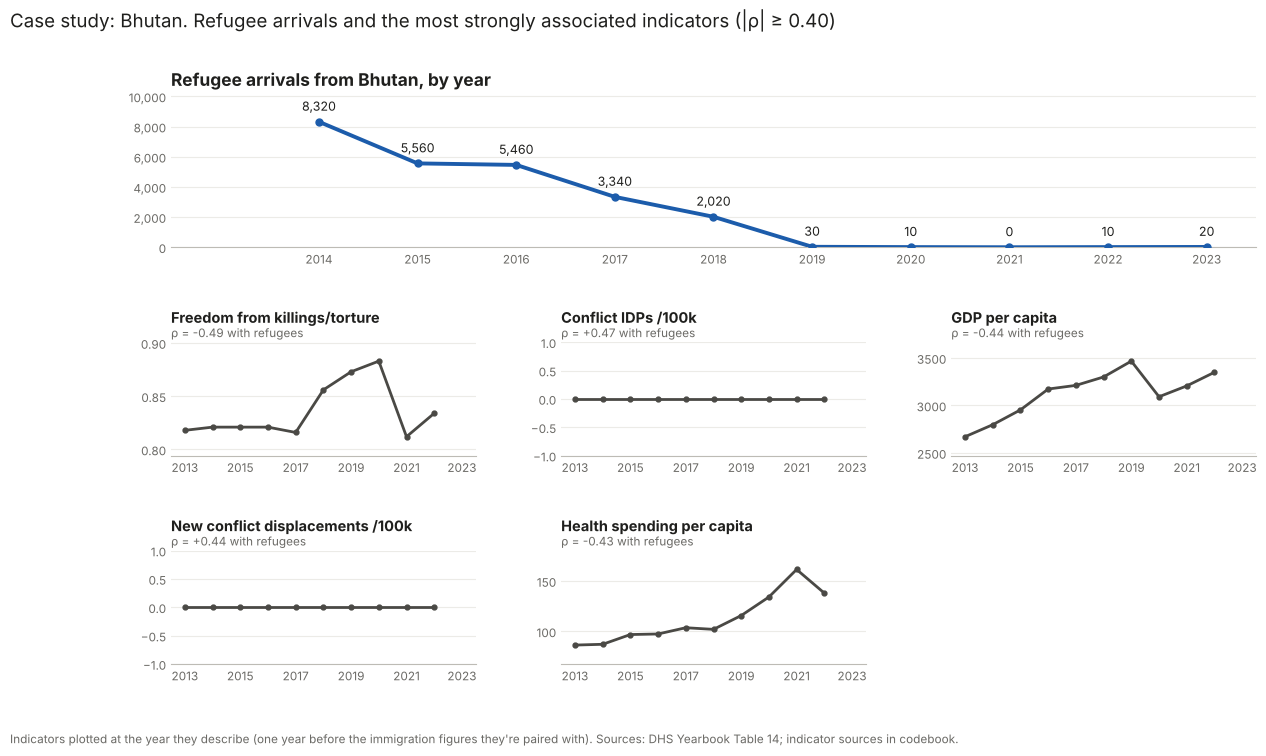

In [24]:
plot_case("Bhutan", "refugees_per_100k", "refugees", "Refugee arrivals", "case_bhutan_refugees.png",
          "DHS Yearbook Table 14")

## Jamaica: green cards

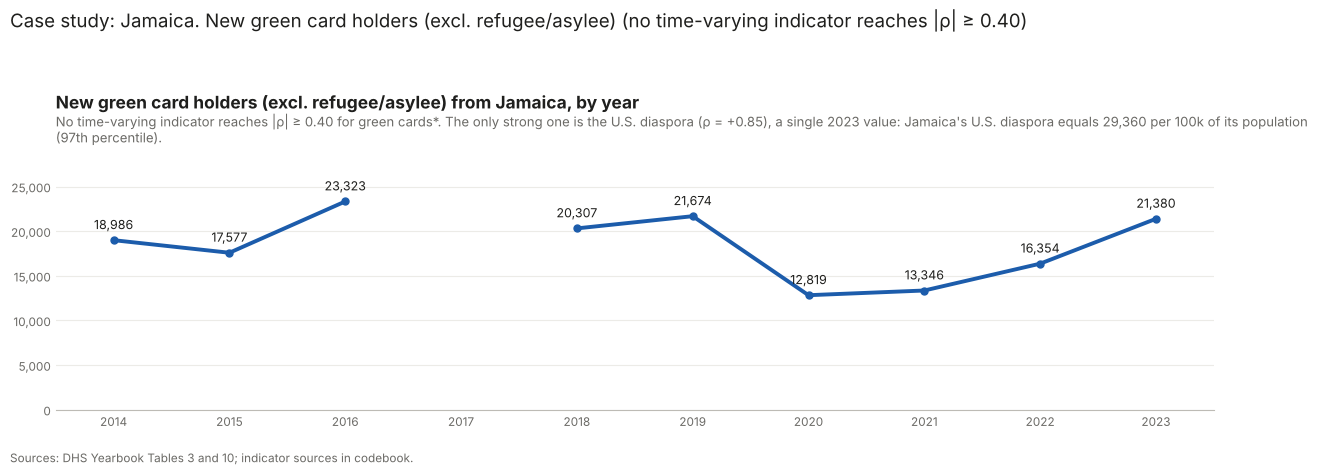

In [25]:
plot_case("Jamaica", "green_cards_excl_refugee_asylee_per_100k", "green_cards_excl_refugee_asylee",
          "New green card holders (excl. refugee/asylee)", "case_jamaica_green_cards.png", "DHS Yearbook Tables 3 and 10")

## El Salvador: asylum grants

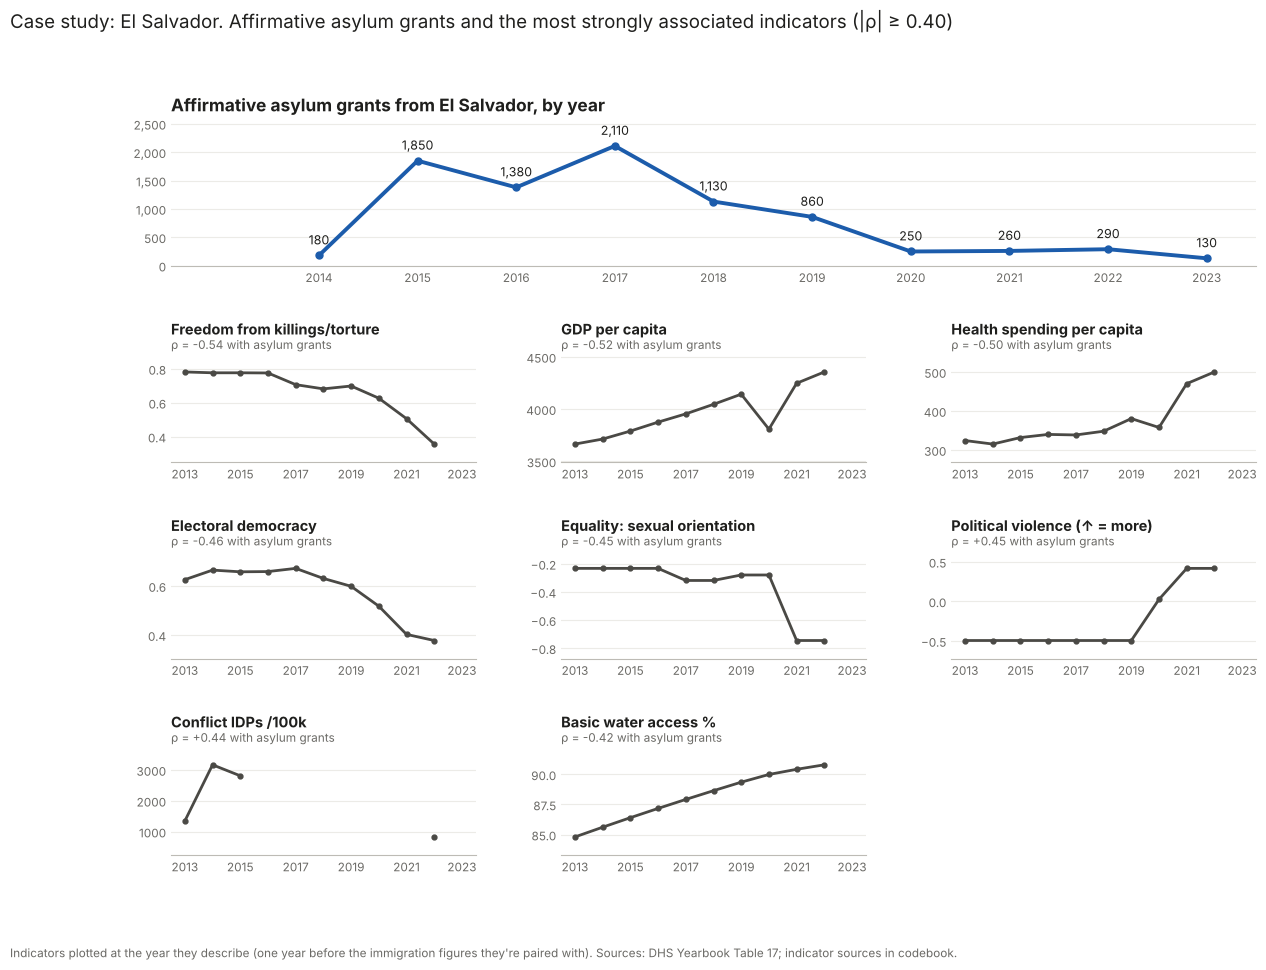

In [26]:
plot_case("El Salvador", "asylum_grants_per_100k", "asylum_grants", "Affirmative asylum grants", "case_el_salvador_asylum.png",
          "DHS Yearbook Table 17")

---
# 6b. Displacement level vs. immigration to the U.S.

Countries are grouped by their **average conflict IDPs per 100k people** (2014–2023, previous-year values):
**None** = no conflict displacement recorded; the rest are split into three equal-sized groups (**Low / Medium / High**).
Each bar is the **median** immigration rate per 100k for countries in that group. Medians are used because a few
outliers (e.g. Bhutan, which has no conflict IDPs but a very high refugee rate) would distort averages.
Each panel has its own scale, since green card and apprehension rates are far larger than refugee or asylum rates.

In [27]:
country_means = df.groupby("country")[["idps_conflict_per_100k_lag1"] + list(outcomes)].mean()
country_means = country_means.dropna(subset=["idps_conflict_per_100k_lag1"])
x = country_means["idps_conflict_per_100k_lag1"]

groups = ["None", "Low", "Medium", "High"]
country_means["displacement_group"] = "None"
nonzero = x > 0
country_means.loc[nonzero, "displacement_group"] = pd.qcut(x[nonzero], 3, labels=groups[1:]).astype(str)

edges = x[nonzero].quantile([0, 1/3, 2/3, 1]).values
ranges = {"None": "0",
          "Low": f"{edges[0]:,.0f}–{edges[1]:,.0f}",
          "Medium": f"{edges[1]:,.0f}–{edges[2]:,.0f}",
          "High": f"{edges[2]:,.0f}+"}

summary = country_means.groupby("displacement_group")[list(outcomes)].median().loc[groups].rename(columns=outcomes)
summary.insert(0, "countries", country_means.groupby("displacement_group").size().loc[groups])
summary.insert(1, "conflict IDPs per 100k", [ranges[g] for g in groups])
summary.round(2)

,countries,conflict IDPs per 100k,Refugees,Apprehensions,Green cards*,Asylum grants
displacement_group,,,,,,
None,131,0,0.00,1.46,11.24,0.00
Low,22,0–132,0.01,1.93,8.20,0.24
Medium,22,"132–1,358",0.02,0.76,6.02,0.13
High,22,"1,358+",1.48,1.03,13.08,0.41


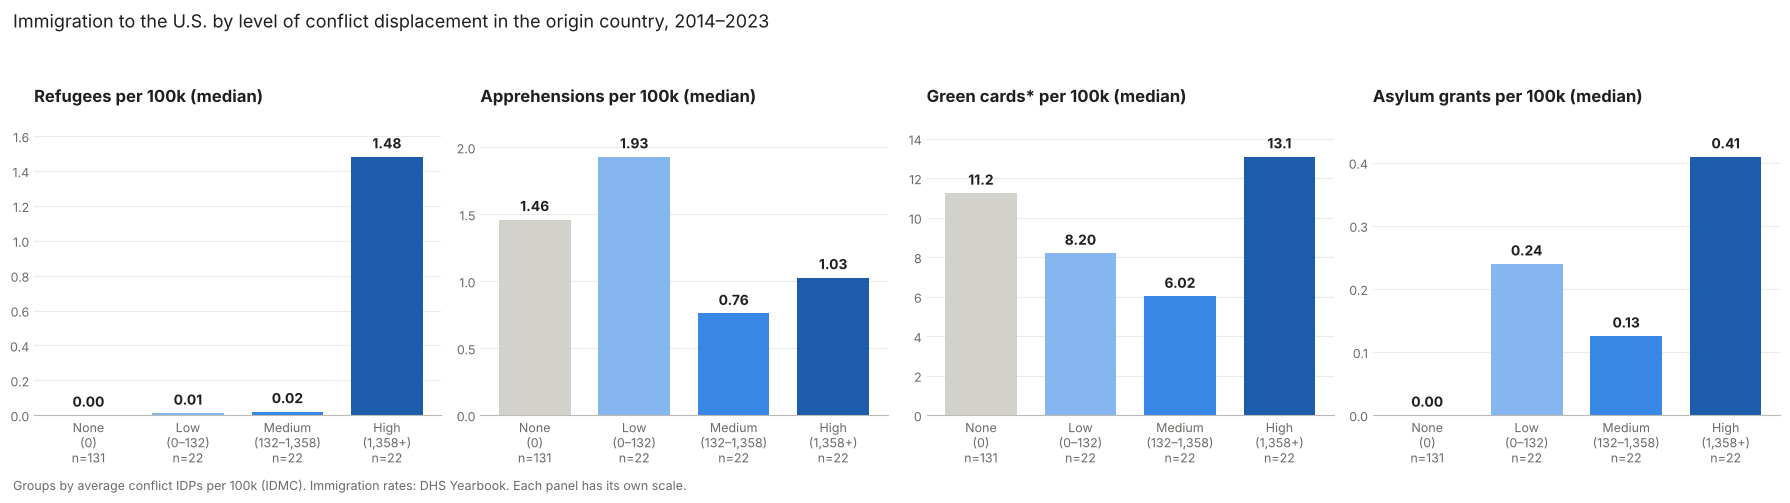

In [28]:
SEQ = ["#d3d1cc", "#86b6ef", "#3987e5", "#1c5cab"]   # gray for 'None', then light -> dark blue
INK, MUTED = "#1f1f1d", "#6b6a66"

fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for ax, (col, label) in zip(axes, outcomes.items()):
    vals = summary[label].values
    bars = ax.bar(range(4), vals, color=SEQ, width=0.72, zorder=2)
    top = vals.max()
    for i, v in enumerate(vals):
        ax.text(i, v + top * 0.02, f"{v:,.2f}" if v < 10 else f"{v:,.1f}", ha="center", va="bottom",
                fontsize=10, color=INK, fontweight="bold")
    ax.set_xticks(range(4), [f"{g}\n({ranges[g]})\nn={summary.loc[g, 'countries']}" for g in groups],
                  fontsize=9, color=MUTED)
    ax.set_ylim(0, top * 1.18)
    ax.set_title(f"{label} per 100k (median)", fontsize=12, color=INK, loc="left", fontweight="bold")
    ax.grid(axis="y", color="#ecebe7", linewidth=0.8, zorder=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#bdbbb5")
    ax.tick_params(axis="y", colors=MUTED, labelsize=9, length=0)
    ax.tick_params(axis="x", length=0)

fig.suptitle("Immigration to the U.S. by level of conflict displacement in the origin country, 2014–2023",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.text(0.01, -0.02, "Groups by average conflict IDPs per 100k (IDMC). Immigration rates: DHS Yearbook. "
         "Each panel has its own scale.", fontsize=9, color=MUTED)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig("displacement_groups_bar.png", dpi=200, bbox_inches="tight")
plt.show()

---
# 7. Which countries best represent the strong indicators?

For each country that sent at least 1,000 people of that type (and in at least 6 years), two scores:
- **Levels match (0–100):** average percentile of the country's strong indicators, flipped so that 100 = the direction
  linked to *more* immigration (e.g. low GDP, low freedom from killings/torture, many conflict IDPs).
- **Over-time agreement (−1 to +1):** within the country, the average Spearman correlation between its yearly numbers and each
  strong indicator, signed so that +1 = the indicator moves the way the cross-country pattern predicts.
  Only indicators that actually vary in that country count.
- **Combined score** = average of the two (time agreement rescaled to 0–1). A representative case scores well on both.

In [29]:
cnt_join = df.merge(counts[["iso3", "year", "green_cards_excl_refugee_asylee", "refugees", "asylum_grants", "apprehensions"]],
                    on=["iso3", "year"])
pct_all = cnt_join.groupby("country").mean(numeric_only=True).rank(pct=True)

def representativeness(outcome_col, count_col, min_total=1000, min_years=6):
    strong_vars, _ = sel[outcome_col]
    rows = []
    for c, g in cnt_join.groupby("country"):
        if g[count_col].sum() < min_total or (g[count_col] > 0).sum() < min_years:
            continue
        lvl = np.nanmean([pct_all.loc[c, v] if r > 0 else 1 - pct_all.loc[c, v] for v, r in strong_vars.items()])
        tr = []
        for v, r in strong_vars.items():
            p = g[[count_col, v]].dropna()
            if len(p) >= 6 and p[v].nunique() > 2 and p[count_col].nunique() > 2:
                tr.append(np.sign(r) * spearmanr(p[count_col], p[v])[0])
        if tr:
            rows.append({"country": c, f"total {count_col}": int(g[count_col].sum()),
                         "rate percentile": round(pct_all.loc[c, outcome_col] * 100),
                         "levels match": round(lvl * 100), "over-time agreement": round(np.mean(tr), 2),
                         "indicators that vary": len(tr)})
    t = pd.DataFrame(rows)
    t["combined score"] = ((t["levels match"] / 100 + (t["over-time agreement"] + 1) / 2) / 2).round(2)
    return t.sort_values("combined score", ascending=False).reset_index(drop=True)

rep_ref = representativeness("refugees_per_100k", "refugees")
rep_ref.head(12)

,country,total refugees,rate percentile,levels match,over-time agreement,indicators that vary,combined score
0,Sudan,9810,92,90,0.38,5,0.80
1,Burundi,3570,94,93,0.26,5,0.78
2,Nepal,1140,87,74,0.56,3,0.76
3,Afghanistan,17410,94,90,0.17,5,0.74
4,Ukraine,21460,95,79,0.37,5,0.74
5,Ethiopia,4910,88,91,0.13,5,0.74
6,Somalia,35750,99,96,-0.02,5,0.72
7,Pakistan,2840,82,84,0.14,5,0.70
8,Myanmar,69850,98,85,0.12,5,0.70
9,Iraq,52320,98,80,0.16,5,0.69


In [30]:
rep_ref[rep_ref.country.isin(["Bhutan"])]

,country,total refugees,rate percentile,levels match,over-time agreement,indicators that vary,combined score
11,Bhutan,24770,100,50,0.67,3,0.67


In [31]:
rep_app = representativeness("apprehensions_per_100k", "apprehensions") if len(sel["apprehensions_per_100k"][0]) else "no strong indicators"
rep_app.head(12) if not isinstance(rep_app, str) else rep_app

'no strong indicators'

In [32]:
rep_asy = representativeness("asylum_grants_per_100k", "asylum_grants")
rep_asy.head(12)

,country,total asylum_grants,rate percentile,levels match,over-time agreement,indicators that vary,combined score
0,Eritrea,1950,99,82,0.36,5,0.75
1,Ethiopia,3690,78,88,0.25,8,0.75
2,Syria,4880,96,90,0.12,7,0.73
3,Afghanistan,16240,98,88,0.07,8,0.71
4,Pakistan,2610,64,79,0.25,8,0.71
5,Nepal,1210,82,64,0.51,7,0.70
6,Egypt,12270,92,75,0.31,7,0.70
7,Venezuela,20850,100,67,0.39,6,0.68
8,Cameroon,1310,84,81,0.12,8,0.68
9,Nigeria,2610,66,75,0.17,7,0.67


In [33]:
rep_asy[rep_asy.country.isin(["El Salvador"])]

,country,total asylum_grants,rate percentile,levels match,over-time agreement,indicators that vary,combined score
20,El Salvador,8440,100,62,-0.12,7,0.53


For green cards the main strong variable is the diaspora, so the check is whether a country's green card rate (excl. refugee/asylee) matches its diaspora.

In [34]:
GCX = "green_cards_excl_refugee_asylee_per_100k"
gc = df.groupby("country")[[GCX, "diaspora_in_us_per_100k_origin_pop"]].mean().dropna()
gc["green card percentile"] = (gc[GCX].rank(pct=True) * 100).round()
gc["diaspora percentile"] = (gc.diaspora_in_us_per_100k_origin_pop.rank(pct=True) * 100).round()
gc.sort_values(GCX, ascending=False).head(12).round(1)

,green_cards_excl_refugee_asylee_per_100k,diaspora_in_us_per_100k_origin_pop,green card percentile,diaspora percentile
country,,,,
Jamaica,654.2,29027.9,100.0,97.0
Guyana,623.1,35531.5,99.0,98.0
Dominica,533.7,44206.6,98.0,99.0
Dominican Republic,442.3,11813.7,98.0,90.0
Grenada,419.7,27154.0,97.0,96.0
St. Lucia,370.3,15478.0,96.0,92.0
El Salvador,347.6,24068.0,95.0,94.0
St. Vincent and the Grenadines,318.7,24958.5,94.0,95.0
Cabo Verde,287.9,6115.9,94.0,85.0


---
# 8. Diaspora share vs. green cards

**U.S. diaspora share** = people born in the country living in the U.S. (2023) as a % of the country's population.
The first chart compares the 20 countries with the largest share; the second tests the relationship across all countries.

In [35]:
pop_raw = pd.read_csv("migration_panel_combined.csv")
dia = pop_raw.groupby("country").agg(diaspora=("diaspora_in_us_2023", "first"),
                                     population=("population_lag1", "mean"),
                                     gc_per_100k=("green_cards_excl_refugee_asylee_per_100k", "mean"),
                                     green_cards=("green_cards_excl_refugee_asylee", "mean")).dropna()
dia["diaspora_pct"] = dia.diaspora / dia.population * 100
top20 = dia.sort_values("diaspora_pct", ascending=False).head(20)
top20[["diaspora_pct", "population", "gc_per_100k"]].round(1)

,diaspora_pct,population,gc_per_100k
country,,,
Marshall Islands,49.9,45695.7,49.6
Dominica,44.2,68625.5,533.7
Guyana,35.5,783887.9,623.1
"Micronesia, Fed. Sts.",31.4,109863.4,15.5
Jamaica,29.0,2815658.2,654.2
Grenada,27.2,115447.7,419.7
St. Vincent and the Grenadines,24.9,105214.8,318.7
El Salvador,24.1,6211270.2,347.6
Barbados,18.6,280285.3,114.9


/tmp/ipykernel_387/85958831.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=(0, 0.025, 1, 0.96))


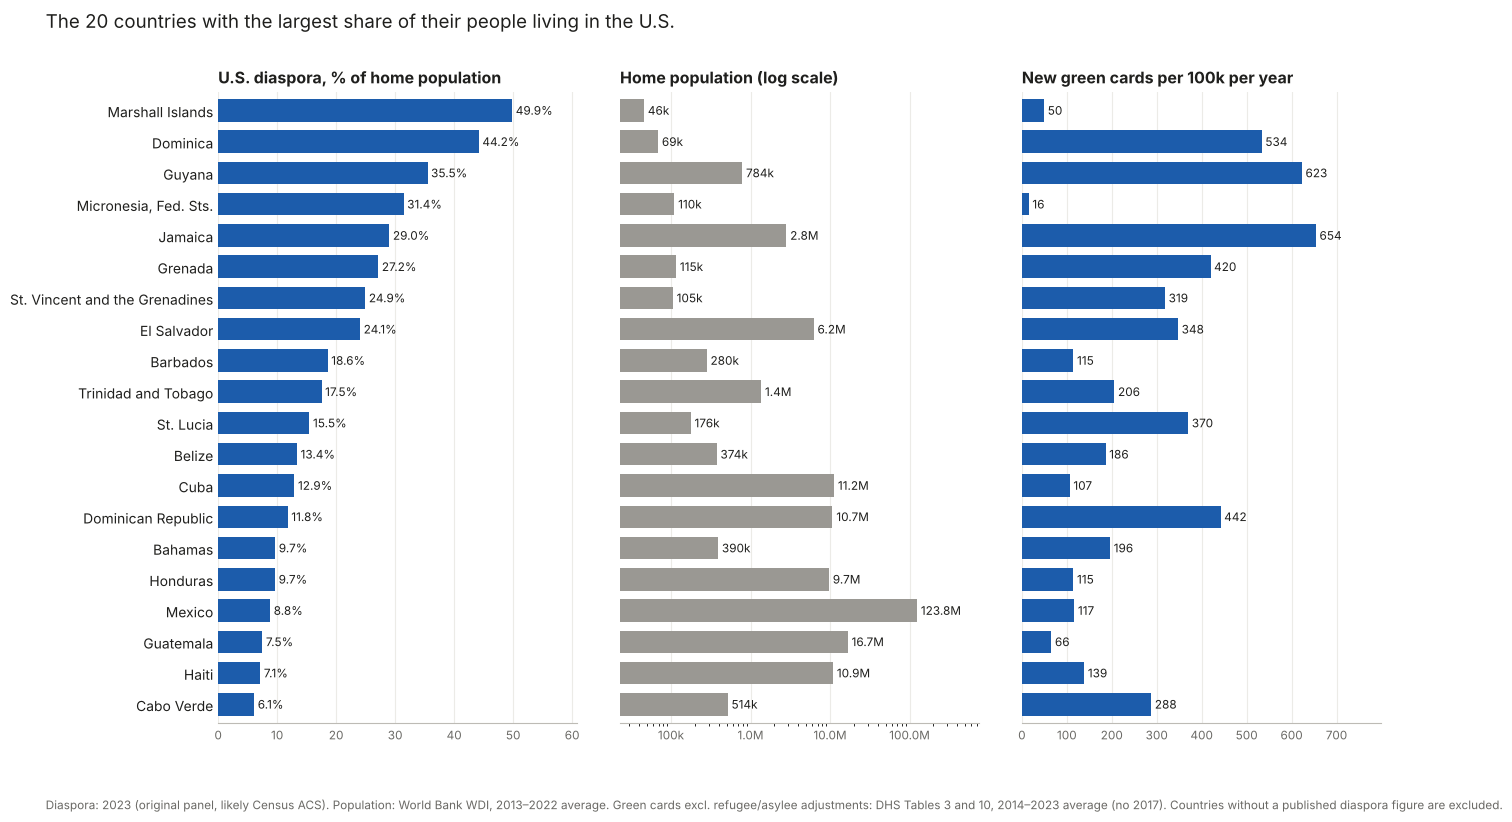

In [36]:
def fmt_pop(v):
    return f"{v/1e6:,.1f}M" if v >= 1e6 else f"{v/1e3:,.0f}k"

t = top20[::-1]
fig, axes = plt.subplots(1, 3, figsize=(15, 8.2), sharey=True, gridspec_kw={"wspace": 0.12})
panels = [("diaspora_pct", "U.S. diaspora, % of home population", lambda v: f"{v:.1f}%", False),
          ("population", "Home population (log scale)", fmt_pop, True),
          ("gc_per_100k", "New green cards per 100k per year", lambda v: f"{v:,.0f}", False)]
for ax, (col, title, fmt_, log) in zip(axes, panels):
    vals = t[col].values
    ax.barh(t.index, vals, color=ACCENT if col != "population" else "#9a9893", height=0.72, zorder=3)
    if log:
        ax.set_xscale("log")
        ax.set_xlim(vals.min() / 2, vals.max() * 6)
    else:
        ax.set_xlim(0, vals.max() * 1.22)
    for y_, v in enumerate(vals):
        ax.text(v * (1.12 if log else 1) + (0 if log else vals.max() * 0.012), y_, fmt_(v), va="center", fontsize=8.5, color=INK)
    ax.set_title(title, fontsize=11.5, color=INK, loc="left", fontweight="bold")
    ax.grid(axis="x", color="#ecebe7", linewidth=0.8, zorder=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#bdbbb5")
    ax.tick_params(axis="y", length=0, labelsize=10, colors=INK)
    ax.tick_params(axis="x", length=0, labelsize=8.5, colors=MUTED)
    ax.set_ylim(-0.6, len(t) - 0.4)
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt_pop(v)))
fig.suptitle("The 20 countries with the largest share of their people living in the U.S.", x=0.01, ha="left", fontsize=13.5, color=INK)
fig.text(0.01, 0.005, "Diaspora: 2023 (original panel, likely Census ACS). Population: World Bank WDI, 2013–2022 average. "
         "Green cards excl. refugee/asylee adjustments: DHS Tables 3 and 10, 2014–2023 average (no 2017). Countries without a published diaspora figure are excluded.",
         fontsize=8.5, color=MUTED)
plt.tight_layout(rect=(0, 0.025, 1, 0.96))
plt.savefig("diaspora_top20_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

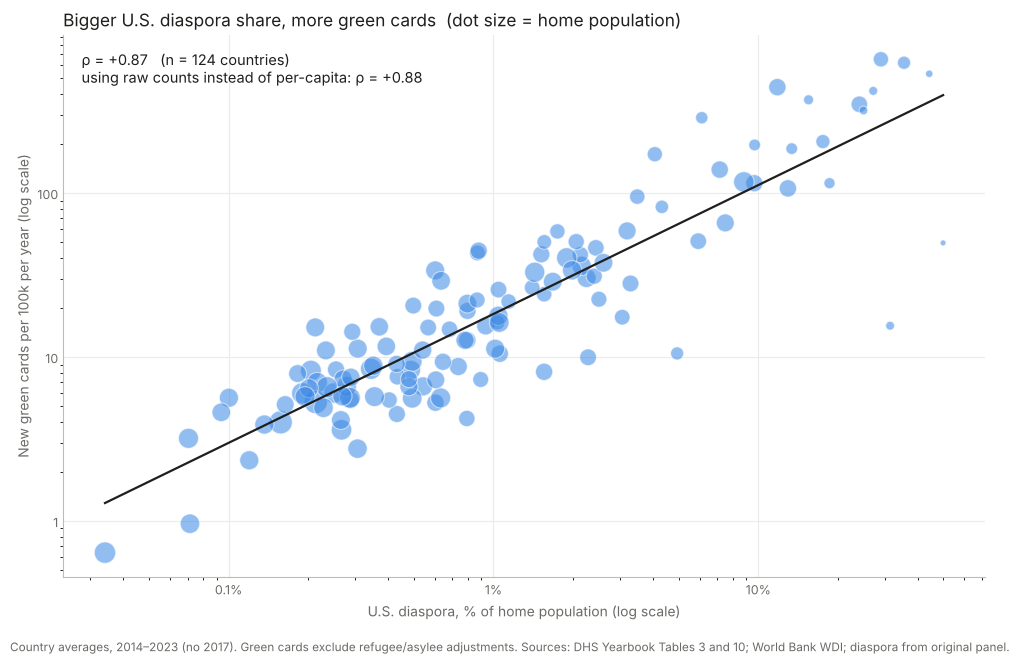

In [37]:
d = dia[(dia.diaspora_pct > 0) & (dia.gc_per_100k > 0)]
rho_dia = spearmanr(dia.diaspora_pct, dia.gc_per_100k)[0]
rho_raw = spearmanr(dia.diaspora, dia.green_cards)[0]

fig, ax = plt.subplots(figsize=(10, 6.6))
sizes = 18 + 260 * (np.log10(d.population) - np.log10(d.population).min()) / np.ptp(np.log10(d.population))
ax.scatter(d.diaspora_pct, d.gc_per_100k, s=sizes, color=DOT, alpha=0.55, edgecolor="white", linewidth=0.8, zorder=3)
b, a = np.polyfit(np.log10(d.diaspora_pct), np.log10(d.gc_per_100k), 1)
xx = np.logspace(np.log10(d.diaspora_pct.min()), np.log10(d.diaspora_pct.max()), 50)
ax.plot(xx, 10 ** (a + b * np.log10(xx)), color=INK, linewidth=1.6, zorder=4)
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}%"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.text(0.02, 0.97, f"ρ = {rho_dia:+.2f}   (n = {len(dia)} countries)\nusing raw counts instead of per-capita: ρ = {rho_raw:+.2f}",
        transform=ax.transAxes, va="top", fontsize=10.5, color=INK)
ax.set_xlabel("U.S. diaspora, % of home population (log scale)", fontsize=10, color=MUTED)
ax.set_ylabel("New green cards per 100k per year (log scale)", fontsize=10, color=MUTED)
ax.set_title("Bigger U.S. diaspora share, more green cards  (dot size = home population)", fontsize=12.5, color=INK, loc="left")
ax.grid(color="#ecebe7", linewidth=0.8, zorder=0)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color("#bdbbb5")
ax.tick_params(colors=MUTED, labelsize=9, length=0)
fig.text(0.01, 0.005, "Country averages, 2014–2023 (no 2017). Green cards exclude refugee/asylee adjustments. Sources: DHS Yearbook Tables 3 and 10; World Bank WDI; diaspora from original panel.",
         fontsize=8.5, color=MUTED)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("diaspora_vs_green_cards_scatter.png", dpi=200, bbox_inches="tight")
plt.show()

---
# 9. Green cards by type

DHS Yearbook **Table 10** splits each country's green cards into six classes of admission. Columns in both CSVs:
`green_cards_family`, `green_cards_employment`, `green_cards_immediate_relatives`, `green_cards_diversity`,
`green_cards_refugee_asylee`, `green_cards_other` (counts in the combined file, `_per_100k` in both).

**The charts below leave out the refugee/asylee class**: those are people already counted as refugees or asylum
grants in earlier years, plus Cuban Adjustment Act cases (which DHS files under "Refugees"). Shares are of
green cards excluding that class.

- **Immediate relatives**: spouses, minor children and parents of U.S. citizens (no annual cap).
- **Family preferences**: adult children and siblings of citizens, and family of green-card holders (capped, long waits).
- **Employment**: workers and their families. **Diversity**: the visa lottery.
- **Refugees & asylees**: people admitted as refugees or granted asylum in earlier years, now adjusting to permanent status.
- **Other**: e.g. Afghan and Iraqi special immigrant visas, cancellation of removal, parolee adjustments.

Gaps: **FY2017 is missing** (the DHS page could not be read). FY2023 values are rounded to the nearest 10 by DHS.
Cells DHS suppressed for privacy ("D") are blank. Mali and Malta FY2023 are blank (DHS appears to have swapped their labels).

In [38]:
GC_TYPES = {
    "green_cards_immediate_relatives": "Immediate relatives",
    "green_cards_family":              "Family preferences",
    "green_cards_employment":          "Employment",
    "green_cards_diversity":           "Diversity lottery",
    "green_cards_other":               "Other",
}
TYPE_COLORS = ["#1c5cab", "#86b6ef", "#e0a32e", "#2a9d8f", "#9a9893"]

gct = pd.read_csv("migration_panel_combined.csv")
gct = gct[gct.year != 2017]                       # no class data for FY2017
tot = gct.groupby("country")[list(GC_TYPES)].sum(min_count=1)
tot["total"] = tot.sum(axis=1)
top15 = tot.sort_values("total", ascending=False).head(15)
share = top15[list(GC_TYPES)].div(top15[list(GC_TYPES)].sum(axis=1), axis=0) * 100
share.rename(columns=GC_TYPES).round(0)

,Immediate relatives,Family preferences,Employment,Diversity lottery,Other
country,,,,,
Mexico,66.0,20.0,5.0,0.0,9.0
India,28.0,17.0,54.0,0.0,1.0
China,40.0,21.0,39.0,0.0,0.0
Dominican Republic,51.0,48.0,1.0,0.0,0.0
Philippines,51.0,25.0,23.0,0.0,1.0
Vietnam,43.0,51.0,6.0,0.0,0.0
El Salvador,55.0,29.0,11.0,0.0,5.0
Jamaica,70.0,25.0,5.0,0.0,0.0
Colombia,75.0,16.0,9.0,0.0,1.0


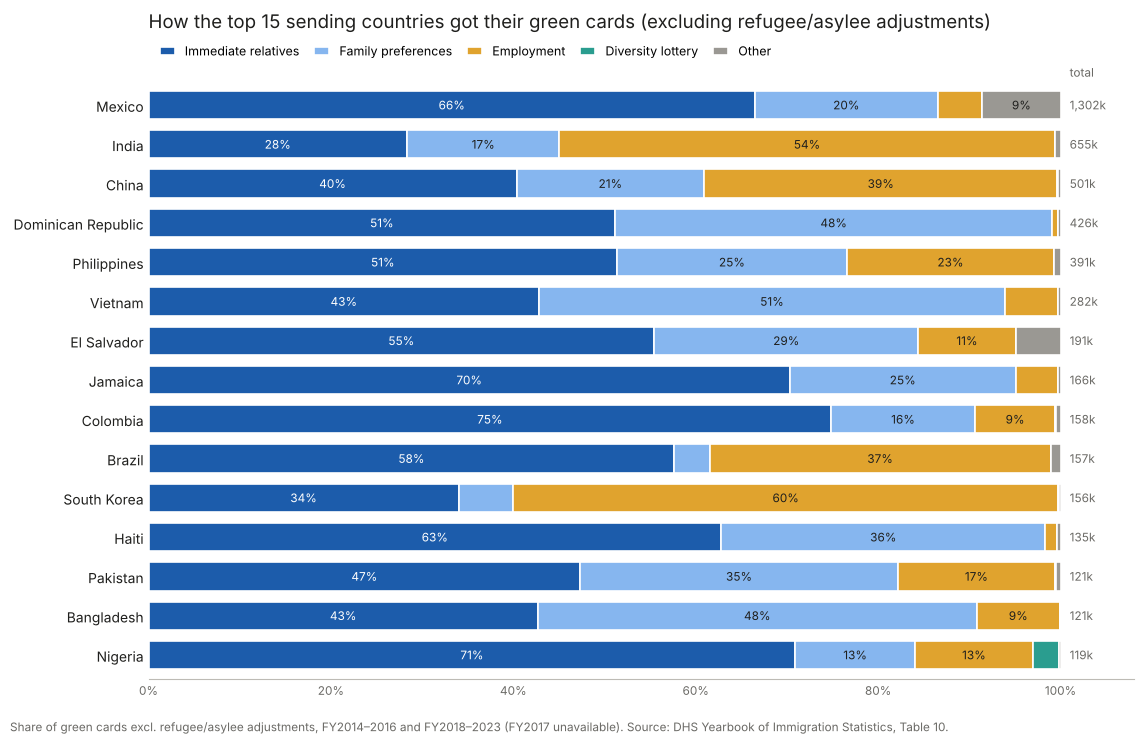

In [39]:
t = share[::-1]
fig, ax = plt.subplots(figsize=(11.5, 7.4))
left = np.zeros(len(t))
for (col, label), color in zip(GC_TYPES.items(), TYPE_COLORS):
    v = t[col].fillna(0).values
    ax.barh(t.index, v, left=left, color=color, height=0.72, label=label, edgecolor="white", linewidth=1.2, zorder=3)
    for y_, (l, w) in enumerate(zip(left, v)):
        if w >= 7:
            ax.text(l + w / 2, y_, f"{w:.0f}%", ha="center", va="center", fontsize=8.5,
                    color="white" if color in ("#1c5cab", "#2a9d8f") else INK)
    left += v
for y_, c in enumerate(t.index):
    ax.text(101, y_, f"{top15.loc[c, 'total'] / 1e3:,.0f}k", va="center", fontsize=8.5, color=MUTED)
ax.text(101, len(t) - 0.35, "total", fontsize=8.5, color=MUTED, va="bottom")
ax.set_xlim(0, 108)
ax.set_ylim(-0.6, len(t) - 0.1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%" if v <= 100 else ""))
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#bdbbb5")
ax.tick_params(axis="y", length=0, labelsize=10, colors=INK)
ax.tick_params(axis="x", length=0, labelsize=8.5, colors=MUTED)
ax.legend(ncol=5, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False, fontsize=9, handlelength=1.2, columnspacing=1.2)
ax.set_title("How the top 15 sending countries got their green cards (excluding refugee/asylee adjustments)", fontsize=13.5, color=INK, loc="left", pad=30)
fig.text(0.01, 0.005, "Share of green cards excl. refugee/asylee adjustments, FY2014–2016 and FY2018–2023 (FY2017 unavailable). "
         "Source: DHS Yearbook of Immigration Statistics, Table 10.", fontsize=8.5, color=MUTED)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("green_card_types_top15.png", dpi=200, bbox_inches="tight")
plt.show()

## Which push factors line up with each kind of green card?

Same method as section 1 (Spearman ρ, country-years pooled, missing values dropped pair by pair), but with the five green card
classes (refugee/asylee excluded) per 100k as the columns. This shows whether a push factor that looks weak for green cards overall is strong for one class.

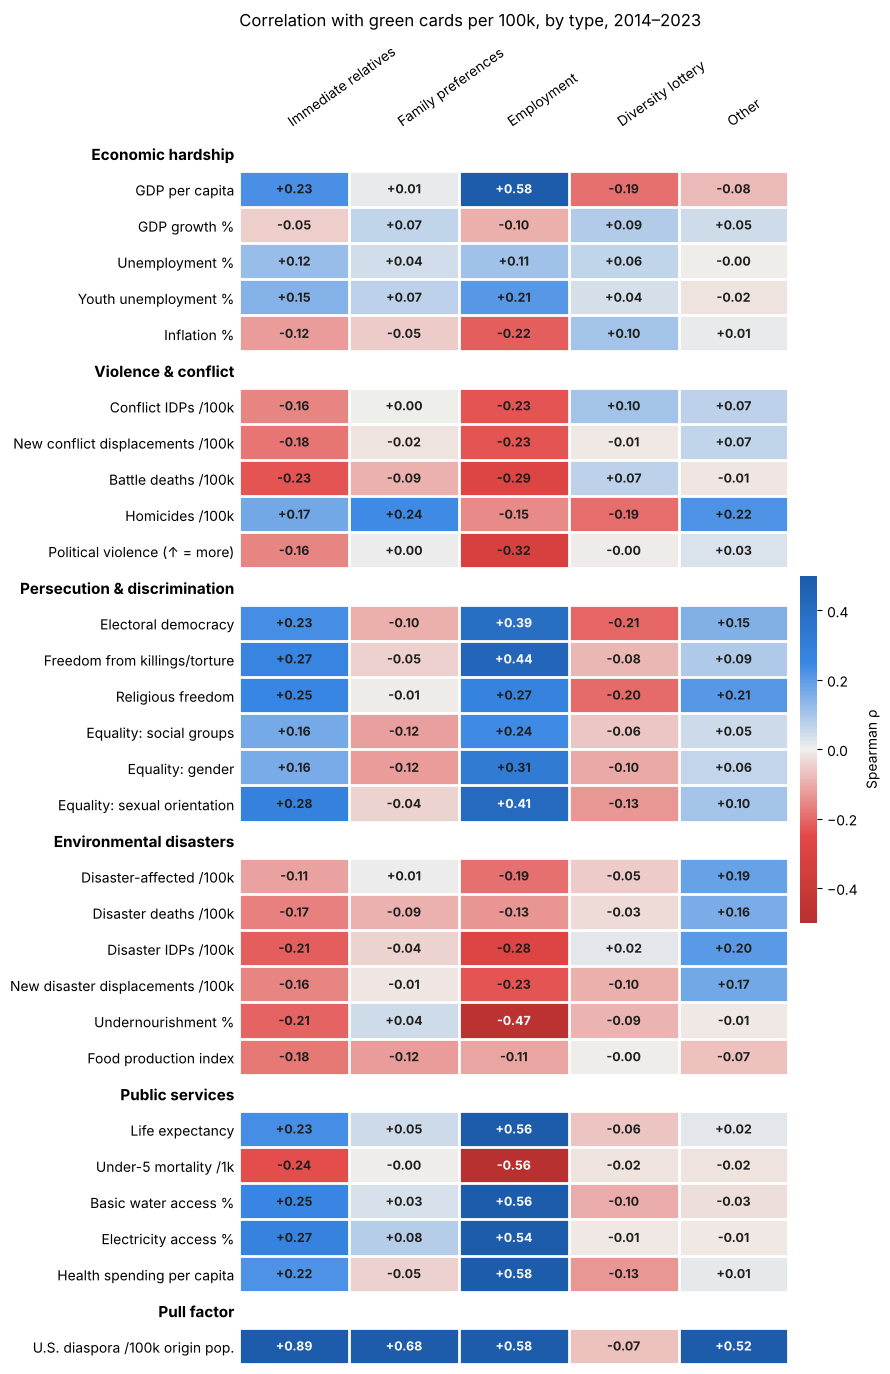

,Immediate relatives,Family preferences,Employment,Diversity lottery,Other
GDP per capita,NaN,NaN,0.58,NaN,NaN
Freedom from killings/torture,NaN,NaN,0.44,NaN,NaN
Equality: sexual orientation,NaN,NaN,0.41,NaN,NaN
Undernourishment %,NaN,NaN,-0.47,NaN,NaN
Life expectancy,NaN,NaN,0.56,NaN,NaN
Under-5 mortality /1k,NaN,NaN,-0.56,NaN,NaN
Basic water access %,NaN,NaN,0.56,NaN,NaN
Electricity access %,NaN,NaN,0.54,NaN,NaN
Health spending per capita,NaN,NaN,0.58,NaN,NaN
U.S. diaspora /100k origin pop.,0.89,0.68,0.58,NaN,0.52


In [40]:
gc_type_outcomes = {c + "_per_100k": l for c, l in GC_TYPES.items()}
rho_t = {}
for col in indicators:
    rho_t[col] = []
    for o in gc_type_outcomes:
        pair = df[[o, col]].dropna()
        rho_t[col].append(spearmanr(pair[o], pair[col])[0])

draw_grouped_heatmap(
    color_vals=rho_t,
    cell_text={c: [f"{r:+.2f}" for r in v] for c, v in rho_t.items()},
    col_labels=list(gc_type_outcomes.values()),
    vmin=-0.5, vmax=0.5,
    cbar_label="Spearman ρ",
    title="Correlation with green cards per 100k, by type, 2014–2023",
    filename="green_card_types_correlation_heatmap.png",
    width=9,
    dark_ink=lambda v: abs(v) > 0.38,
)
strong_t = pd.DataFrame(rho_t, index=gc_type_outcomes.values()).T.rename(index=indicators)
strong_t[(strong_t.abs() >= 0.40)].dropna(how="all").round(2)